In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr


import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

In [3]:
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)
print(f"Kích thước bộ dữ liệu: {df.shape}")
df.head()


Kích thước bộ dữ liệu: (507, 22)


,ID,Truong,Khoi,Phai,tg_sudung_dt,Q1,Q2,Q3,Q4,Q5,...,Q8,Q9,Q10,Tong,addiction,Level,id,name,rating,created_at
0,anhn85782@gmail.com,1,1,0,7.0,4,4,2,4,2,...,2,5,3,38.0,0.63,1,NaN,NaN,NaN,NaN
1,thu.nnm1812-k32sinh@thd.edu.vn,1,1,0,5.0,5,4,4,2,4,...,4,5,2,40.0,0.67,2,NaN,NaN,NaN,NaN
2,lucyngoc2009@gmail.com,1,1,0,8.0,2,5,3,3,2,...,5,5,2,44.0,0.73,2,NaN,NaN,NaN,NaN
3,trang.ndh-k32sinh@thd.edu.vn,1,1,0,4.0,4,4,4,4,4,...,2,5,2,37.0,0.62,1,NaN,NaN,NaN,NaN
4,ngamy160709@gmail.com,1,1,0,4.0,4,1,1,1,1,...,4,1,1,23.0,0.38,0,NaN,NaN,NaN,NaN


In [4]:
# =========================================================================
# CHUẨN HÓA CỘT 'Phai' VÀ 'Truong' (CHUYỂN DẠNG CHỮ VỀ DẠNG SỐ 0, 1)
# =========================================================================

# 1. Chuẩn hóa cột 'Phai' (Giới tính: 0 = Nữ, 1 = Nam)
def standardize_phai(val):
    if pd.isna(val):
        return val
    val_str = str(val).strip().lower()
    # Nếu là Nữ / nữ / 0 -> trả về 0
    if val_str in ['Ná»¯']:
        return 0
    # Nếu là Nam / nam / 1 -> trả về 1
    elif val_str in ['1', '1.0', 'Nam', 'male']:
        return 1
    return val

if 'Phai' in df.columns:
    df['Phai'] = df['Phai'].apply(standardize_phai)

# 2. Chuẩn hóa cột 'Truong' (Trường: 1 = Chuyên Trần Hưng Đạo, 0 = Trường khác)
def standardize_truong(val):
    if pd.isna(val):
        return val
    val_str = str(val).strip().lower()
    # Nếu có chữ 'trần hưng đạo' hoặc số 1 -> trả về 1
    if 'trần hưng đạo' in val_str or val_str in ['THPT TRáº¦N HÆ¯NG Äáº O']:
        return 1
    # Nếu là trường khác hoặc số 0 -> trả về 0
    else:
        return 0

if 'Truong' in df.columns:
    df['Truong'] = df['Truong'].apply(standardize_truong)

print("✅ Đã chuẩn hóa thành công các cột chữ thành số (Phái: 0=Nữ/1=Nam, Trường: 1=Chuyên/0=Khác)!")

✅ Đã chuẩn hóa thành công các cột chữ thành số (Phái: 0=Nữ/1=Nam, Trường: 1=Chuyên/0=Khác)!


In [5]:
import pandas as pd
import numpy as np

# =========================================================================
# CHUẨN HÓA DỨT ĐIỂM CỘT 'Phai' VÀ 'Truong' CHO TOÀN BỘ 507 MẪU
# =========================================================================

# 1. Hàm chuẩn hóa Cột 'Phai' (0 = Nữ, 1 = Nam)
def fix_phai(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip().lower()

    # Kiểm tra Nam hoặc số 1
    if 'nam' in val_str or val_str in ['1', '1.0']:
        return 1
    # Kiểm tra Nữ hoặc số 0
    elif 'nữ' in val_str or 'nu' in val_str or val_str in ['0', '0.0']:
        return 0
    return 0  # Giá trị mặc định nếu có ngoại lệ

# 2. Hàm chuẩn hóa Cột 'Truong' (1 = Chuyên Trần Hưng Đạo, 0 = Trường khác)
def fix_truong(val):
    if pd.isna(val):
        return 0
    val_str = str(val).strip().lower()

    # Tất cả các biến thể của Trần Hưng Đạo hoặc số 1 -> ép về 1
    if 'trần hưng đạo' in val_str or 'tran hung dao' in val_str or val_str in ['1', '1.0']:
        return 1
    # Tất cả các trường khác (Hàm Thuận Nam, Kim Thành, Phan Bội Châu...) hoặc số 0 -> ép về 0
    else:
        return 0

# Áp dụng trực tiếp lên DataFrame df
df['Phai'] = df['Phai'].apply(fix_phai).astype(int)
df['Truong'] = df['Truong'].apply(fix_truong).astype(int)

# =========================================================================
# KIỂM TRA LẠI KẾT QUẢ SAU KIỂU CHUẨN HÓA
# =========================================================================
print("✅ CHUẨN HÓA THÀNH CÔNG CHO TỔNG SỐ 507 MẪU!\n")

print("--- Thống kê Cột 'Phai' (Giới tính) ---")
print(f"0 (Nữ):  {sum(df['Phai'] == 0)} thí sinh")
print(f"1 (Nam): {sum(df['Phai'] == 1)} thí sinh")
print(f"Tổng:    {len(df)} thí sinh")

print("\n--- Thống kê Cột 'Truong' (Trường học) ---")
print(f"1 (Chuyên Trần Hưng Đạo): {sum(df['Truong'] == 1)} thí sinh")
print(f"0 (Trường khác trong tỉnh): {sum(df['Truong'] == 0)} thí sinh")
print(f"Tổng:    {len(df)} thí sinh")

✅ CHUẨN HÓA THÀNH CÔNG CHO TỔNG SỐ 507 MẪU!

--- Thống kê Cột 'Phai' (Giới tính) ---
0 (Nữ):  268 thí sinh
1 (Nam): 239 thí sinh
Tổng:    507 thí sinh

--- Thống kê Cột 'Truong' (Trường học) ---
1 (Chuyên Trần Hưng Đạo): 10 thí sinh
0 (Trường khác trong tỉnh): 497 thí sinh
Tổng:    507 thí sinh


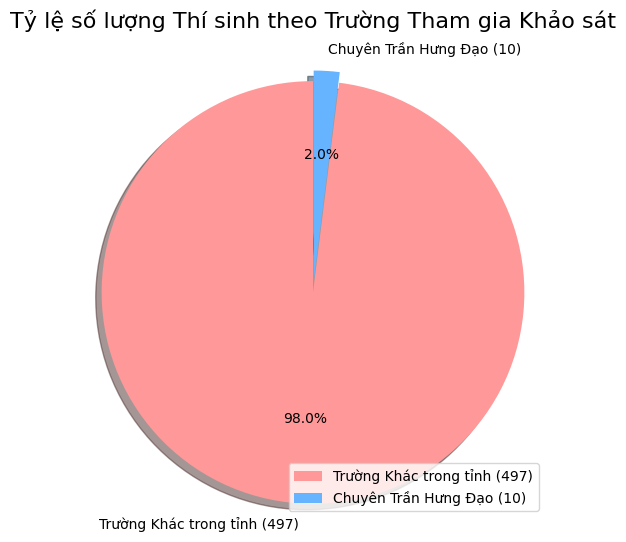


--- Thống kê Số lượng Thí sinh ---
Chuyên Trần Hưng Đạo (1): 10 thí sinh
Trường Khác (0):          497 thí sinh
Tổng số thí sinh (df):    507 thí sinh


In [6]:
import matplotlib.pyplot as plt

# 1. Tự động tính toán số lượng thí sinh theo từng trường từ df mới
# Cột 'Truong': 1 = Chuyên Trần Hưng Đạo, 0 = Trường khác
count_0 = (df['Truong'] == 0).sum()
count_1 = (df['Truong'] == 1).sum()

# 2. Định nghĩa nhãn tự động cập nhật số lượng (Dùng f-string)
labels = [
    f'Trường Khác trong tỉnh ({count_0})',
    f'Chuyên Trần Hưng Đạo ({count_1})'
]
sizes = [count_0, count_1]
colors = ['#ff9999', '#66b3ff']
explode = (0.05, 0)

# 3. Vẽ biểu đồ tròn
plt.figure(figsize=(6, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
        autopct='%1.1f%%',
        shadow=True, startangle=90)

plt.title('Tỷ lệ số lượng Thí sinh theo Trường Tham gia Khảo sát', fontsize=16, pad=20)
plt.axis('equal')
plt.legend(labels, loc="lower right")
plt.show()

# Hiển thị dữ liệu thống kê cơ bản
print("\n--- Thống kê Số lượng Thí sinh ---")
print(f"Chuyên Trần Hưng Đạo (1): {count_1} thí sinh")
print(f"Trường Khác (0):          {count_0} thí sinh")
print(f"Tổng số thí sinh (df):    {len(df)} thí sinh")

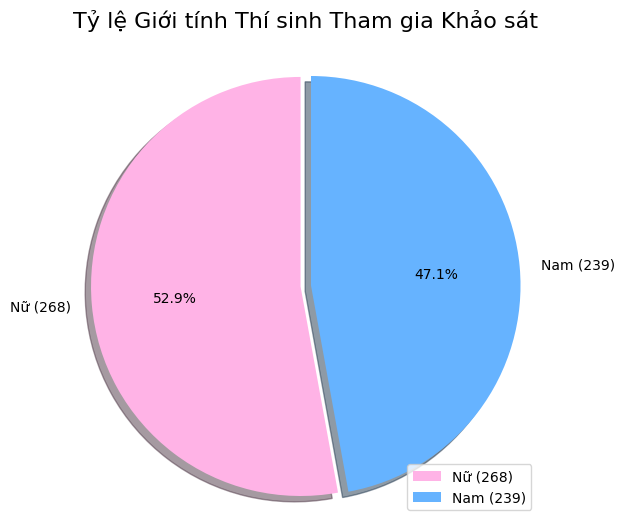


--- Thống kê Số lượng Thí sinh theo Giới tính ---
Số lượng Nữ (0):  268 thí sinh
Số lượng Nam (1): 239 thí sinh
Tổng số thí sinh: 507 thí sinh


In [7]:
import matplotlib.pyplot as plt

# 1. Tính toán chính xác số lượng Nữ và Nam từ tập dữ liệu mới (df)
# Cột 'Phai': 0 = Nữ, 1 = Nam
count_female = (df['Phai'] == 0).sum()
count_male = (df['Phai'] == 1).sum()

# 2. Định nghĩa nhãn tự động cập nhật số lượng thực tế
labels = [
    f'Nữ ({count_female})',
    f'Nam ({count_male})'
]
sizes = [count_female, count_male]
colors = ['#ffb3e6', '#66b3ff']  # Màu Hồng cho Nữ, Xanh cho Nam

# Tự động đẩy nhẹ (explode) miếng bánh có số lượng lớn hơn
explode = (0.05, 0) if count_female >= count_male else (0, 0.05)

# 3. Vẽ biểu đồ tròn
plt.figure(figsize=(6, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
        autopct='%1.1f%%',
        shadow=True, startangle=90)

plt.title('Tỷ lệ Giới tính Thí sinh Tham gia Khảo sát', fontsize=16, pad=20)
plt.axis('equal')
plt.legend(labels, loc="best")
plt.show()

# Hiển thị dữ liệu thống kê cơ bản
print("\n--- Thống kê Số lượng Thí sinh theo Giới tính ---")
print(f"Số lượng Nữ (0):  {count_female} thí sinh")
print(f"Số lượng Nam (1): {count_male} thí sinh")
print(f"Tổng số thí sinh: {len(df)} thí sinh")

--- Kết quả Phân tích Tương quan Pearson ---
Hệ số Tương quan (r): 0.0218
Giá trị p (p-value): 6.2379e-01
=> Mối tương quan: không đáng kể (hoặc không có ý nghĩa thống kê) và mang tính thuận
=> P-value < 0.05 cho thấy mối quan hệ có ý nghĩa thống kê (Reject H0).


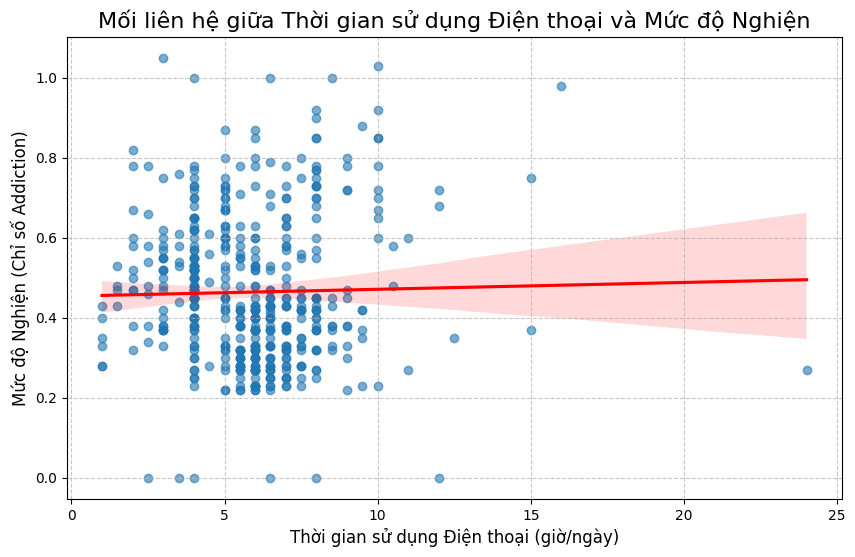

In [8]:
# 1. Tính toán Hệ số Tương quan Pearson
# Giả định cột 'addiction' là kết quả chuẩn hóa của 'Tong'
correlation, p_value = pearsonr(df['tg_sudung_dt'], df['addiction'])

# 2. In kết quả tương quan
print("--- Kết quả Phân tích Tương quan Pearson ---")
print(f"Hệ số Tương quan (r): {correlation:.4f}")
print(f"Giá trị p (p-value): {p_value:.4e}")

# Giải thích kết quả
if p_value < 0.05 and correlation > 0.5:
    strength = "rất mạnh"
elif p_value < 0.05 and correlation > 0.3:
    strength = "trung bình đến mạnh"
elif p_value < 0.05 and correlation > 0.1:
    strength = "yếu"
else:
    strength = "không đáng kể (hoặc không có ý nghĩa thống kê)"

print(f"=> Mối tương quan: {strength} và mang tính {('thuận' if correlation > 0 else 'nghịch')}")
print(f"=> P-value < 0.05 cho thấy mối quan hệ có ý nghĩa thống kê (Reject H0).")


# 3. Vẽ Biểu đồ Phân tán (Scatter Plot)
plt.figure(figsize=(10, 6))
# Sử dụng seaborn để thêm đường hồi quy tuyến tính (regression line)
sns.regplot(x='tg_sudung_dt', y='addiction', data=df,
            scatter_kws={'alpha':0.6}, line_kws={'color': 'red'})

plt.title('Mối liên hệ giữa Thời gian sử dụng Điện thoại và Mức độ Nghiện', fontsize=16)
plt.xlabel('Thời gian sử dụng Điện thoại (giờ/ngày)', fontsize=12)
plt.ylabel('Mức độ Nghiện (Chỉ số Addiction)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

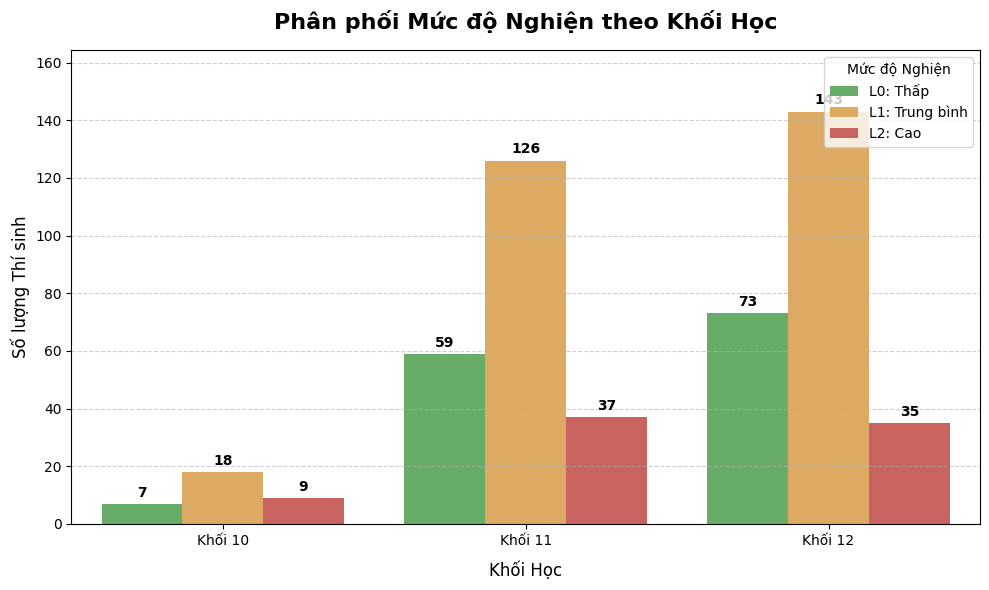

✅ Đã tạo và lưu thành công Biểu đồ Cột Nhóm: 'grouped_bar_chart_level_by_khoi_rerun.png'

--- 📊 Bảng Thống kê Tần suất Mức độ Nghiện theo Khối Học ---
Level_Label  L0: Thấp  L1: Trung bình  L2: Cao
Khoi_Label                                    
Khối 10             7              18        9
Khối 11            59             126       37
Khối 12            73             143       35


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Đọc và gộp dữ liệu
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)

# Chuẩn hóa tên cột (loại bỏ khoảng trắng thừa)
df.columns = df.columns.str.strip()

# --- 2. HÀM CHUẨN HÓA DỮ LIỆU AN TOÀN (XỬ LÝ DẠNG SỐ CẢ DẠNG CHỮ) ---
def standardize_level(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip().lower()
    if val_str in ['0', '0.0', 'l0', 'l0: thấp', 'thấp', 'thap']:
        return 'L0: Thấp'
    elif val_str in ['1', '1.0', 'l1', 'l1: trung bình', 'trung bình', 'trung binh']:
        return 'L1: Trung bình'
    elif val_str in ['2', '2.0', 'l2', 'l2: cao', 'cao']:
        return 'L2: Cao'
    return np.nan

def standardize_khoi(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip().lower()
    if val_str in ['0', '0.0', '10', '10.0', 'khối 10', 'khoi 10']:
        return 'Khối 10'
    elif val_str in ['1', '1.0', '11', '11.0', 'khối 11', 'khoi 11']:
        return 'Khối 11'
    elif val_str in ['2', '2.0', '12', '12.0', 'khối 12', 'khoi 12']:
        return 'Khối 12'
    return np.nan

# Áp dụng chuẩn hóa
df['Level_Label'] = df['Level'].apply(standardize_level)
df['Khoi_Label'] = df['Khoi'].apply(standardize_khoi)

# --- 3. Tính toán số lượng theo Khối và Level ---
khoi_order = ['Khối 10', 'Khối 11', 'Khối 12']
level_order = ['L0: Thấp', 'L1: Trung bình', 'L2: Cao']

cross_tab = pd.crosstab(df['Khoi_Label'], df['Level_Label'])
# Đảm bảo giữ đúng thứ tự và không bỏ sót nhóm nào
cross_tab = cross_tab.reindex(index=khoi_order, columns=level_order, fill_value=0)

df_plot = cross_tab.stack().reset_index(name='Số lượng')
df_plot.columns = ['Khối', 'Mức độ Nghiện', 'Số lượng']

# --- 4. Vẽ Biểu đồ Cột Nhóm ---
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x='Khối',
    y='Số lượng',
    hue='Mức độ Nghiện',
    data=df_plot,
    palette=['#5cb85c', '#f0ad4e', '#d9534f'],
    order=khoi_order
)

# Hiển thị con số chính xác trên đỉnh mỗi cột
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

# Thiết lập tiêu đề và nhãn
plt.title('Phân phối Mức độ Nghiện theo Khối Học', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Khối Học', fontsize=12, labelpad=10)
plt.ylabel('Số lượng Thí sinh', fontsize=12)
plt.legend(title='Mức độ Nghiện', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Mở rộng giới hạn trục Y để số hiển thị không bị chạm viền
if not df_plot['Số lượng'].empty:
    plt.ylim(0, df_plot['Số lượng'].max() * 1.15)

plt.tight_layout()
plt.savefig('grouped_bar_chart_level_by_khoi_rerun.png', dpi=300)
plt.show()

print("✅ Đã tạo và lưu thành công Biểu đồ Cột Nhóm: 'grouped_bar_chart_level_by_khoi_rerun.png'")

# Hiển thị bảng tần suất
print("\n--- 📊 Bảng Thống kê Tần suất Mức độ Nghiện theo Khối Học ---")
print(cross_tab)

/tmp/ipykernel_5132/624851479.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Hệ số Tương quan (r)', y='Câu Hỏi', data=corr_df, palette='Reds_d')


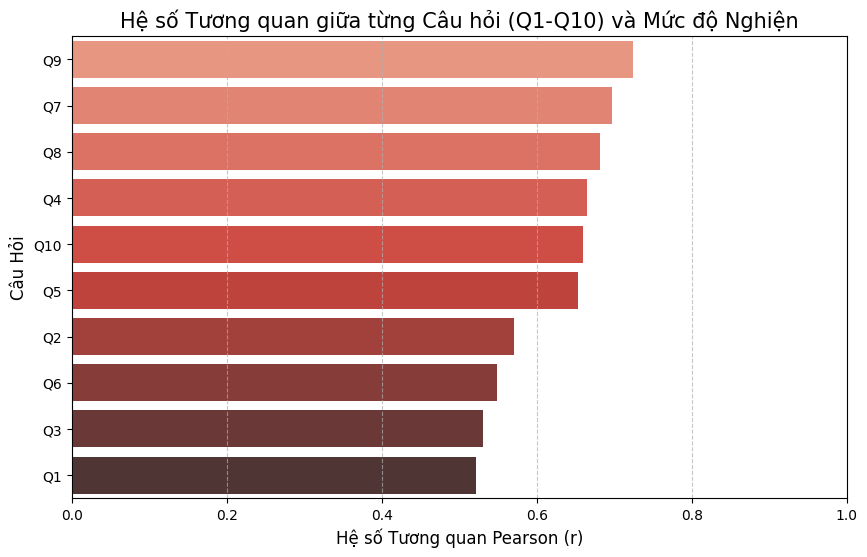

--- Bảng xếp hạng các Yếu tố Tương quan với Mức độ Nghiện ---
  Câu Hỏi  Hệ số Tương quan (r)
8      Q9              0.723839
6      Q7              0.697067
7      Q8              0.681163
3      Q4              0.665000
9     Q10              0.659838
4      Q5              0.652593
1      Q2              0.570315
5      Q6              0.548173
2      Q3              0.530295
0      Q1              0.521752


In [10]:
# 1. Tính toán Tương quan
# Khai báo các cột Q1 đến Q10
q_cols = [f'Q{i}' for i in range(1, 11)]

# Tính tương quan Pearson giữa mỗi cột Q và cột 'addiction'
correlations = {}
for q in q_cols:
    # pearsonr trả về (hệ số tương quan, p-value)
    corr_value = df[q].corr(df['addiction'], method='pearson')
    correlations[q] = corr_value

# Chuyển kết quả sang DataFrame và sắp xếp theo tương quan giảm dần
corr_df = pd.DataFrame(list(correlations.items()), columns=['Câu Hỏi', 'Hệ số Tương quan (r)'])
corr_df = corr_df.sort_values(by='Hệ số Tương quan (r)', ascending=False)

# 2. Vẽ Biểu đồ Cột Tương quan
plt.figure(figsize=(10, 6))
sns.barplot(x='Hệ số Tương quan (r)', y='Câu Hỏi', data=corr_df, palette='Reds_d')

plt.title('Hệ số Tương quan giữa từng Câu hỏi (Q1-Q10) và Mức độ Nghiện', fontsize=15)
plt.xlabel('Hệ số Tương quan Pearson (r)', fontsize=12)
plt.ylabel('Câu Hỏi', fontsize=12)
plt.xlim(0, 1.0)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

print("--- Bảng xếp hạng các Yếu tố Tương quan với Mức độ Nghiện ---")
print(corr_df)

In [11]:
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)
df.info()
df.describe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 507 entries, 0 to 506
Data columns (total 22 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ID            184 non-null    object 
 1   Truong        507 non-null    object 
 2   Khoi          507 non-null    int64  
 3   Phai          507 non-null    object 
 4   tg_sudung_dt  507 non-null    float64
 5   Q1            507 non-null    int64  
 6   Q2            507 non-null    int64  
 7   Q3            507 non-null    int64  
 8   Q4            507 non-null    int64  
 9   Q5            507 non-null    int64  
 10  Q6            507 non-null    int64  
 11  Q7            507 non-null    int64  
 12  Q8            507 non-null    int64  
 13  Q9            507 non-null    int64  
 14  Q10           507 non-null    int64  
 15  Tong          507 non-null    float64
 16  addiction     507 non-null    float64
 17  Level         507 non-null    int64  
 18  id            323 non-null    

<bound method NDFrame.describe of                                  ID                                    Truong  \
0               anhn85782@gmail.com                                         1   
1    thu.nnm1812-k32sinh@thd.edu.vn                                         1   
2            lucyngoc2009@gmail.com                                         1   
3      trang.ndh-k32sinh@thd.edu.vn                                         1   
4             ngamy160709@gmail.com                                         1   
..                              ...                                       ...   
502                             NaN  Trường Trung học Phổ Thông Hàm Thuận Nam   
503                             NaN  Trường Trung học Phổ Thông Hàm Thuận Nam   
504                             NaN  Trường Trung học Phổ Thông Hàm Thuận Nam   
505                             NaN  Trường Trung học Phổ Thông Hàm Thuận Nam   
506                             NaN  Trường Trung học Phổ Thông Hàm Thuận Nam   

     Khoi Phai  tg_sudung_dt  Q1  Q2  Q3  Q4  Q5  ...  Q8  Q9  Q10  Tong  \
0       1    0           7.0   4   4   2   4   2  ...   2   5    3  38.0   
1       1    0           5.0   5   4   4   2   4  ...   4   5    2  40.0   
2       1    0           8.0   2   5   3   3   2  ...   5   5    2  44.0   
3       1    0           4.0   4   4   4   4   4  ...   2   5    2  37.0   
4       1    0           4.0   4   1   1   1   1  ...   4   1    1  23.0   
..    ...  ...           ...  ..  ..  ..  ..  ..  ...  ..  ..  ...   ...   
502    12   Nữ           7.0   2   2   2   2   2  ...   1   1    1  15.0   
503    12  Nam           8.0   1   2   2   2   2  ...   2   2    2  19.0   
504    12  Nam           6.0   2   2   2   2   1  ...   2   2    2  17.0   
505    12  Nam           5.5   2   2   2   2   2  ...   3   3    3  25.0   
506    12   Nữ           6.0   2   2   2   2   1  ...   2   2    3  18.0   

     addiction  Level     id              name  rating  \
0         0.63      1    NaN               NaN     NaN   
1         0.67      2    NaN               NaN     NaN   
2         0.73      2    NaN               NaN     NaN   
3         0.62      1    NaN               NaN     NaN   
4         0.38      0    NaN               NaN     NaN   
..         ...    ...    ...               ...     ...   
502       0.25      0  320.0  LÊ TRẦN BẢO TRÂN     5.0   
503       0.32      1  321.0  NGUYỄN TRẦN VIỆT     5.0   
504       0.28      0  322.0        BÙI THẾ VŨ     4.0   
505       0.42      1  323.0      LÂM DU VƯƠNG     5.0   
506       0.30      0  324.0  VÕ NGỌC TƯỜNG VY     5.0   

                        created_at  
0                              NaN  
1                              NaN  
2                              NaN  
3                              NaN  
4                              NaN  
..                             ...  
502  2026-10-16 18:38:05.585055+00  
503  2026-10-16 18:38:52.770563+00  
504  2026-10-16 18:39:33.921709+00  
505  2026-10-16 18:40:09.517969+00  
506   2026-10-16 18:40:45.10993+00  

[507 rows x 22 columns]>

In [14]:

#1: TIỀN XỬ LÝ DỮ LIỆU VÀ CÂN BẰNG DỮ LIỆU BẰNG SMOTE (ĐÃ CHỈNH SỬA)
import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE



# 2. Danh sách các cột cần loại bỏ:
cols_to_drop = ['ID', 'id', 'name', 'rating', 'created_at', 'addiction', 'Tong', 'Level']

# Tự động lọc các cột thực sự có trong DataFrame để tránh lỗi KeyError
existing_cols_to_drop = [col for col in cols_to_drop if col in df.columns]

# Tách đặc trưng (X) và nhãn mục tiêu (y)
X = df.drop(columns=existing_cols_to_drop)
y = df['Level']

# 3. Chuyển đổi toàn bộ biến dạng chữ/phân loại sang dạng số (One-Hot Encoding)
# Bắt buộc vì SMOTE chỉ tính toán được trên dữ liệu dạng số
X = pd.get_dummies(X, drop_first=True)

# 4. Kiểm tra phân bố các lớp trước khi áp dụng SMOTE
print("📊 Phân bố các lớp TRƯỚC KHI SMOTE:")
print(y.value_counts().sort_index())
print("-" * 55)

# 5. Khởi tạo và thực hiện SMOTE
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X, y)

# 6. Đóng gói lại thành DataFrame chuẩn 'df_balanced' phục vụ cho Cell 2 -> Cell 7
df_balanced = pd.DataFrame(X_balanced, columns=X.columns)
df_balanced['Level'] = y_balanced

# 7. Kiểm tra kết quả sau khi cân bằng
print("✅ Phân bố các lớp SAU KHI SMOTE:")
print(df_balanced['Level'].value_counts().sort_index())
print(f"\n✅ Tổng số mẫu sau cân bằng: {df_balanced.shape[0]} dòng, {df_balanced.shape[1]} cột")

📊 Phân bố các lớp TRƯỚC KHI SMOTE:
Level
0    139
1    287
2     81
Name: count, dtype: int64
-------------------------------------------------------
✅ Phân bố các lớp SAU KHI SMOTE:
Level
0    287
1    287
2    287
Name: count, dtype: int64

✅ Tổng số mẫu sau cân bằng: 861 dòng, 38 cột


In [15]:

# CHIA TẬP DỮ LIỆU (TRAIN/TEST SPLIT) VÀ CHUẨN HÓA (SCALING)


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Chia tập Train (80%) và Test (20%), phân bổ đều các lớp (stratify=y_balanced)
X_train, X_test, y_train, y_test = train_test_split(
    df_balanced.drop(columns=['Level']),
    df_balanced['Level'],
    test_size=0.2,
    random_state=42,
    stratify=df_balanced['Level']
)

# 2. Khởi tạo và áp dụng StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Hiển thị thông tin kích thước tập dữ liệu
print(f"✅ Kích thước tập Train: {X_train_scaled.shape[0]} mẫu, {X_train_scaled.shape[1]} đặc trưng")
print(f"✅ Kích thước tập Test:  {X_test_scaled.shape[0]} mẫu, {X_test_scaled.shape[1]} đặc trưng")

✅ Kích thước tập Train: 688 mẫu, 37 đặc trưng
✅ Kích thước tập Test:  173 mẫu, 37 đặc trưng


In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical


# 1. TIỀN XỬ LÝ DỮ LIỆU & CÂN BẰNG (SMOTE)
data = df.copy()

# A. Loại bỏ các cột không dùng làm đặc trưng (chứa thông tin rác / ID / chữ)
cols_to_drop = ['ID', 'id', 'name', 'rating', 'created_at', 'addiction', 'Level']
existing_cols_to_drop = [col for col in cols_to_drop if col in data.columns]

X = data.drop(columns=existing_cols_to_drop)
Y = data['Level']

# B. Xử lý ngoại lai (Capping) cho tg_sudung_dt (nếu cột này tồn tại)
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X.columns:
    Q1 = X[feature_outlier].quantile(0.25)
    Q3 = X[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR  # Đã sửa lỗi thiếu dấu '*'
    X[feature_outlier] = np.where(X[feature_outlier] > upper_bound, upper_bound, X[feature_outlier])

# C. Mã hóa các biến phân loại (Truong, Khoi, Phai hoặc các biến kiểu object/category khác)
cat_cols = [c for c in ['Truong', 'Khoi', 'Phai'] if c in X.columns]
if cat_cols:
    X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
else:
    X_encoded = pd.get_dummies(X, drop_first=True)

# D. Ép kiểu dữ liệu về dạng số và xử lý giá trị rỗng (NaN) trước khi dùng SMOTE
X_encoded = X_encoded.apply(pd.to_numeric, errors='coerce')
X_encoded = X_encoded.fillna(X_encoded.median())

# Đảm bảo Y không chứa giá trị rỗng và đúng kiểu số nguyên
valid_idx = Y.notna()
X_encoded = X_encoded[valid_idx]
Y = Y[valid_idx].astype(int)

# E. Áp dụng SMOTE để cân bằng dữ liệu
sm = SMOTE(sampling_strategy='auto', random_state=42)
X_smote_capped, Y_smote_capped = sm.fit_resample(X_encoded, Y)

# 2. CHUẨN BỊ DỮ LIỆU CHO MẠNG NƠ-RON

# A. Tách tập Huấn luyện và Kiểm tra
X_train, X_test, Y_train, Y_test = train_test_split(
    X_smote_capped, Y_smote_capped, test_size=0.2, random_state=42, stratify=Y_smote_capped
)

# B. Chuẩn hóa Dữ liệu (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# C. Mã hóa One-Hot cho biến mục tiêu Y
Y_train_one_hot = to_categorical(Y_train)
Y_test_one_hot = to_categorical(Y_test)

# Số lượng đặc trưng đầu vào và số lớp đầu ra
input_dim = X_train_scaled.shape[1]
output_classes = Y_train_one_hot.shape[1]

# 3. XÂY DỰNG CẤU TRÚC MÔ HÌNH (SEQUENTIAL MODEL)
tf.random.set_seed(42)

model = Sequential([
    # Lớp Ẩn 1: 64 nơ-ron
    Dense(64, activation='relu', input_shape=(input_dim,)),
    Dropout(0.2),

    # Lớp Ẩn 2: 32 nơ-ron
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),

    # Lớp Đầu ra: Softmax cho phân loại đa lớp
    Dense(output_classes, activation='softmax')
])

# Biên dịch mô hình
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\n--- Tóm tắt Cấu trúc Mạng Nơ-ron ---")
model.summary()

# 4. HUẤN LUYỆN MÔ HÌNH


print("\n--- Bắt đầu Huấn luyện Mô hình ---")
history = model.fit(
    X_train_scaled,
    Y_train_one_hot,
    epochs=200,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

print("\n✅ Huấn luyện hoàn tất.")


--- Tóm tắt Cấu trúc Mạng Nơ-ron ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         2,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,411 (21.14 KB)

 Trainable params: 5,411 (21.14 KB)

 Non-trainable params: 0 (0.00 B)


--- Bắt đầu Huấn luyện Mô hình ---
Epoch 1/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.5800 - loss: 0.9625 - val_accuracy: 0.7681 - val_loss: 0.7075
Epoch 2/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7254 - loss: 0.7015 - val_accuracy: 0.8696 - val_loss: 0.4929
Epoch 3/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7706 - loss: 0.5836 - val_accuracy: 0.8696 - val_loss: 0.3844
Epoch 4/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8126 - loss: 0.4873 - val_accuracy: 0.8986 - val_loss: 0.3260
Epoch 5/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8352 - loss: 0.3984 - val_accuracy: 0.8986 - val_loss: 0.2835
Epoch 6/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8869 - loss: 0.3385 - val_accuracy: 0.9275 - val_loss: 0.2261
Epoch 7/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8934 - loss: 0.3032 - val_accuracy: 0.9420 - val_loss: 0.2048
Epoch 8/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.89

In [18]:
# --- 5. Đánh giá Mô hình ---

# Dự đoán trên tập kiểm tra
Y_pred_prob = model.predict(X_test_scaled)

# Chuyển xác suất dự đoán thành lớp (lấy lớp có xác suất cao nhất)
Y_pred_class = np.argmax(Y_pred_prob, axis=1)

# Chuyển đổi Y_test (One-Hot) về dạng lớp để so sánh
Y_test_class = np.argmax(Y_test_one_hot, axis=1)

print("\n--- Báo cáo Phân loại Mạng Nơ-ron ---")
print(classification_report(Y_test_class, Y_pred_class, target_names=['Level 0', 'Level 1', 'Level 2']))

print("\n--- Ma trận Nhầm lẫn (Confusion Matrix) ---")
print(confusion_matrix(Y_test_class, Y_pred_class))

#

# --- 6. Kết quả Cuối cùng ---
loss, accuracy = model.evaluate(X_test_scaled, Y_test_one_hot, verbose=0)
print(f"\nĐộ chính xác (Accuracy) trên tập kiểm tra: {accuracy*100:.2f}%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

--- Báo cáo Phân loại Mạng Nơ-ron ---
              precision    recall  f1-score   support

     Level 0       0.96      0.95      0.96        57
     Level 1       0.93      0.93      0.93        58
     Level 2       0.97      0.98      0.97        58

    accuracy                           0.95       173
   macro avg       0.95      0.95      0.95       173
weighted avg       0.95      0.95      0.95       173


--- Ma trận Nhầm lẫn (Confusion Matrix) ---
[[54  3  0]
 [ 2 54  2]
 [ 0  1 57]]

Độ chính xác (Accuracy) trên tập kiểm tra: 95.38%


In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical


# 1. TIỀN XỬ LÝ VÀ TÁCH TẬP DỮ LIỆU
data = df.copy()

# Loại bỏ các cột không sử dụng (kiểm tra sự tồn tại để tránh lỗi KeyError)
cols_to_drop = ['ID', 'addiction', 'id', 'name', 'rating', 'created_at']
existing_drop = [c for c in cols_to_drop if c in data.columns]
data_clean = data.drop(columns=existing_drop)

X_original = data_clean.drop(columns=['Level'])
Y = data_clean['Level'].astype(int)

# Xử lý Ngoại lai (Capping) cho 'tg_sudung_dt'
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_original.columns:
    Q1 = X_original[feature_outlier].quantile(0.25)
    Q3 = X_original[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR  # Sửa lỗi cú pháp thiếu dấu '*'
    X_capped = X_original.copy()
    X_capped[feature_outlier] = np.where(X_capped[feature_outlier] > upper_bound, upper_bound, X_capped[feature_outlier])
else:
    X_capped = X_original.copy()

# Mã hóa Phân loại (One-Hot Encoding)
cat_cols = [c for c in ['Truong', 'Khoi', 'Phai'] if c in X_capped.columns]
if cat_cols:
    X_encoded = pd.get_dummies(X_capped, columns=cat_cols, drop_first=True)
else:
    X_encoded = pd.get_dummies(X_capped, drop_first=True)

# Tách tập Train (80%) và Test (20%) TRƯỚC KHI TĂNG MẪU (Đúng phương pháp chuẩn)
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_encoded, Y, test_size=0.2, random_state=42, stratify=Y
)

# Áp dụng SMOTE CÂN BẰNG DỮ LIỆU (Chỉ thực hiện trên tập Train để tránh Data Leakage)
sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm.fit_resample(X_train_raw, Y_train_raw)

# Chuẩn hóa Dữ liệu (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test_raw)  # Dùng transform thay vì fit_transform cho test set

# Mã hóa One-Hot cho biến mục tiêu Y
Y_train_one_hot = to_categorical(Y_train_res)
Y_test_one_hot = to_categorical(Y_test_raw)

input_dim = X_train_scaled.shape[1]
output_classes = Y_train_one_hot.shape[1]

# 2. XÂY DỰNG VÀ HUẤN LUYỆN MÔ HÌNH FNN

tf.random.set_seed(42)

model = Sequential([
    Dense(64, activation='relu', input_shape=(input_dim,)),
    Dense(32, activation='relu'),
    Dense(output_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Huấn luyện mô hình
model.fit(X_train_scaled, Y_train_one_hot, epochs=100, batch_size=16, verbose=0)

# 3. TÍNH TOÁN MA TRẬN NHẦM LẪN VÀ PHẦN TRĂM

Y_pred_prob = model.predict(X_test_scaled, verbose=0)
Y_pred_class = np.argmax(Y_pred_prob, axis=1)
Y_test_class = np.argmax(Y_test_one_hot, axis=1)

cm = confusion_matrix(Y_test_class, Y_pred_class)

# Tính tổng số mẫu trên mỗi hàng (mẫu thực tế của từng lớp)
cm_sum = cm.sum(axis=1)[:, np.newaxis]

# Tính Ma trận Nhầm lẫn theo Phần trăm (%)
cm_percent = np.divide(cm, cm_sum, out=np.zeros_like(cm, dtype=float), where=cm_sum!=0) * 100

print("--- MA TRẬN NHẦM LẪN (Dạng Số lượng) ---")
cm_df_count = pd.DataFrame(
    cm,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count)

print("-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
print("Phần trăm thể hiện: Trong số các mẫu Level X thực tế, có bao nhiêu % được dự đoán là Level Y.\n")

cm_df_percent = pd.DataFrame(
    cm_percent,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)

print(cm_df_percent.astype(str) + '%')

print("-" * 50)

# 4. PHÂN TÍCH CHI TIẾT TỶ LỆ DỰ ĐOÁN ĐÚNG (RECALL) VÀ NHẦM LẪN


print("--- PHÂN TÍCH TỶ LỆ DỰ ĐOÁN ĐÚNG (RECALL) VÀ NHẦM LẪN ---")
print(f"✅ Level 0 (Thấp): {cm_df_percent.iloc[0, 0]:.1f}% được dự đoán đúng.")
print(f"❌ Level 0 (Thấp): {cm_df_percent.iloc[0, 1] + cm_df_percent.iloc[0, 2]:.1f}% bị nhầm sang L1 hoặc L2.")

print(f"\n✅ Level 2 (Cao): {cm_df_percent.iloc[2, 2]:.1f}% được dự đoán đúng (Tỷ lệ tìm thấy rủi ro cao).")
print(f"❌ Level 2 (Cao): {cm_df_percent.iloc[2, 0] + cm_df_percent.iloc[2, 1]:.1f}% bị nhầm sang L0 hoặc L1 (Lỗi Đánh giá thấp rủi ro).")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


--- MA TRẬN NHẦM LẪN (Dạng Số lượng) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          27           1           0
Thực tế L1           2          53           3
Thực tế L2           0           2          14
--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
Phần trăm thể hiện: Trong số các mẫu Level X thực tế, có bao nhiêu % được dự đoán là Level Y.

           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      96.4%       3.6%       0.0%
Thực tế L1       3.4%      91.4%       5.2%
Thực tế L2       0.0%      12.5%      87.5%
--------------------------------------------------
--- PHÂN TÍCH TỶ LỆ DỰ ĐOÁN ĐÚNG (RECALL) VÀ NHẦM LẪN ---
✅ Level 0 (Thấp): 96.4% được dự đoán đúng.
❌ Level 0 (Thấp): 3.6% bị nhầm sang L1 hoặc L2.

✅ Level 2 (Cao): 87.5% được dự đoán đúng (Tỷ lệ tìm thấy rủi ro cao).
❌ Level 2 (Cao): 12.5% bị nhầm sang L0 hoặc L1 (Lỗi Đánh giá thấp rủi ro).


Huấn luyện FNN


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical


# 1. KHAI BÁO 7 ĐẶC TRƯNG & XỬ LÝ DỮ LIỆU ĐẦU VÀO (CHỐNG LỖI NaN/ĐỊNH DẠNG)
selected_features = ['Tong', 'tg_sudung_dt', 'Q8', 'Q9', 'Q4', 'Q7', 'Q3']

# Lọc lấy các đặc trưng có sẵn trong dữ liệu
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

# Ép kiểu dữ liệu về dạng số và xử lý các giá trị khuyết (NaN) phát sinh từ dữ liệu mới
X_original = X_original.apply(pd.to_numeric, errors='coerce')
X_original = X_original.fillna(X_original.median())

# Loại bỏ hàng có biến mục tiêu Y bị rỗng (nếu có)
valid_idx = Y.notna()
X_original = X_original[valid_idx]
Y = Y[valid_idx].astype(int)

# 2. TÁCH TẬP TRAIN / TEST TRƯỚC KHI XỬ LÝ (CHỐNG LEAKAGE)

X_train, X_test, Y_train, Y_test = train_test_split(
    X_original, Y, test_size=0.2, random_state=42, stratify=Y
)

# 3. XỬ LÝ NGOẠI LAI (IQR CAPPING CHO tg_sudung_dt)
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_train.columns:
    Q1 = X_train[feature_outlier].quantile(0.25)
    Q3 = X_train[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR  # Đã sửa lỗi cú pháp thiếu dấu *
    lower_bound = Q1 - 1.5 * IQR  # Đã sửa lỗi cú pháp thiếu dấu *

    X_train_capped = X_train.copy()
    X_test_capped = X_test.copy()

    X_train_capped[feature_outlier] = np.clip(X_train_capped[feature_outlier], lower_bound, upper_bound)
    X_test_capped[feature_outlier] = np.clip(X_test_capped[feature_outlier], lower_bound, upper_bound)
else:
    X_train_capped = X_train.copy()
    X_test_capped = X_test.copy()

# 4. CHUẨN HÓA VÀ CÂN BẰNG DỮ LIỆU (SMOTE CHỈ ÁP DỤNG TRÊN TẬP TRAIN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_capped)
X_test_scaled = scaler.transform(X_test_capped)

sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm.fit_resample(X_train_scaled, Y_train)

Y_train_one_hot = to_categorical(Y_train_res)
Y_test_one_hot = to_categorical(Y_test)

input_dim = X_train_res.shape[1]
output_classes = Y_train_one_hot.shape[1]

# 5. XÂY DỰNG MÔ HÌNH FNN VỚI 3 LỚP ẨN

tf.random.set_seed(42)

model = Sequential([
    Dense(64, activation='relu', input_shape=(input_dim,)),  # Lớp ẩn 1
    Dense(32, activation='relu'),                            # Lớp ẩn 2
    Dense(16, activation='relu'),                            # Lớp ẩn 3
    Dense(output_classes, activation='softmax')               # Lớp đầu ra
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("🚀 Đang huấn luyện mô hình FNN (3 lớp ẩn) với 7 đặc trưng...")
model.fit(X_train_res, Y_train_one_hot, epochs=300, batch_size=16, verbose=0)

# 6. DỰ ĐOÁN VÀ ĐÁNH GIÁ MA TRẬN NHẦM LẪN
Y_pred_prob = model.predict(X_test_scaled, verbose=0)
Y_pred_class = np.argmax(Y_pred_prob, axis=1)
Y_test_class = Y_test.values

# Tính Ma trận Nhầm lẫn
cm = confusion_matrix(Y_test_class, Y_pred_class)
cm_sum = cm.sum(axis=1)[:, np.newaxis]

# Sửa lỗi tính toán phần trăm và phép nhân 100
cm_percent = np.divide(cm, cm_sum, out=np.zeros_like(cm, dtype=float), where=cm_sum != 0) * 100

accuracy = accuracy_score(Y_test_class, Y_pred_class)

# 7. HIỂN THỊ KẾT QUẢ SỐ LƯỢNG
print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
print("Bảng thể hiện số lượng mẫu thực tế thuộc Level X được dự đoán là Level Y.\n")

cm_df_count = pd.DataFrame(
    cm,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)

print(cm_df_count)
print("-" * 60)

print("--- ĐÁNH GIÁ HIỆU SUẤT TỔNG THỂ ---")
print(f"Độ chính xác (Accuracy) tổng thể trên tập kiểm tra: {accuracy*100:.2f}%")
print("-" * 60)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


🚀 Đang huấn luyện mô hình FNN (3 lớp ẩn) với 7 đặc trưng...



--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
Bảng thể hiện số lượng mẫu thực tế thuộc Level X được dự đoán là Level Y.

            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          26           2           0
Thực tế L1           0          58           0
Thực tế L2           0           1          15
------------------------------------------------------------
--- ĐÁNH GIÁ HIỆU SUẤT TỔNG THỂ ---
Độ chính xác (Accuracy) tổng thể trên tập kiểm tra: 97.06%
------------------------------------------------------------


In [21]:
accuracy

0.9705882352941176

📊 BẢNG XẾP HẠNG MỨC ĐỘ QUAN TRỌNG CỦA CÁC ĐẶC TRƯNG
     Feature  Importance  Percentage (%)
        Tong    0.390174           39.02
          Q9    0.107619           10.76
tg_sudung_dt    0.082632            8.26
          Q7    0.080121            8.01
         Q10    0.072463            7.25
          Q4    0.061683            6.17
          Q8    0.051818            5.18
          Q5    0.041018            4.10
          Q3    0.033962            3.40
          Q2    0.029196            2.92
          Q1    0.027883            2.79
          Q6    0.021432            2.14

📌 PHÂN TÍCH ĐÁNH GIÁ:
- Đặc trưng tổng điểm ('Tong') chiếm tới: 39.02% mức độ quan trọng.
- Tất cả 11 đặc trưng còn lại cộng lại chỉ chiếm: 60.98%.
=> Kết luận: Mô hình bị phụ thuộc quá lớn vào 'Tong', dẫn đến hiện tượng át vía (dominated) các đặc trưng thành phần (Q1-Q10).


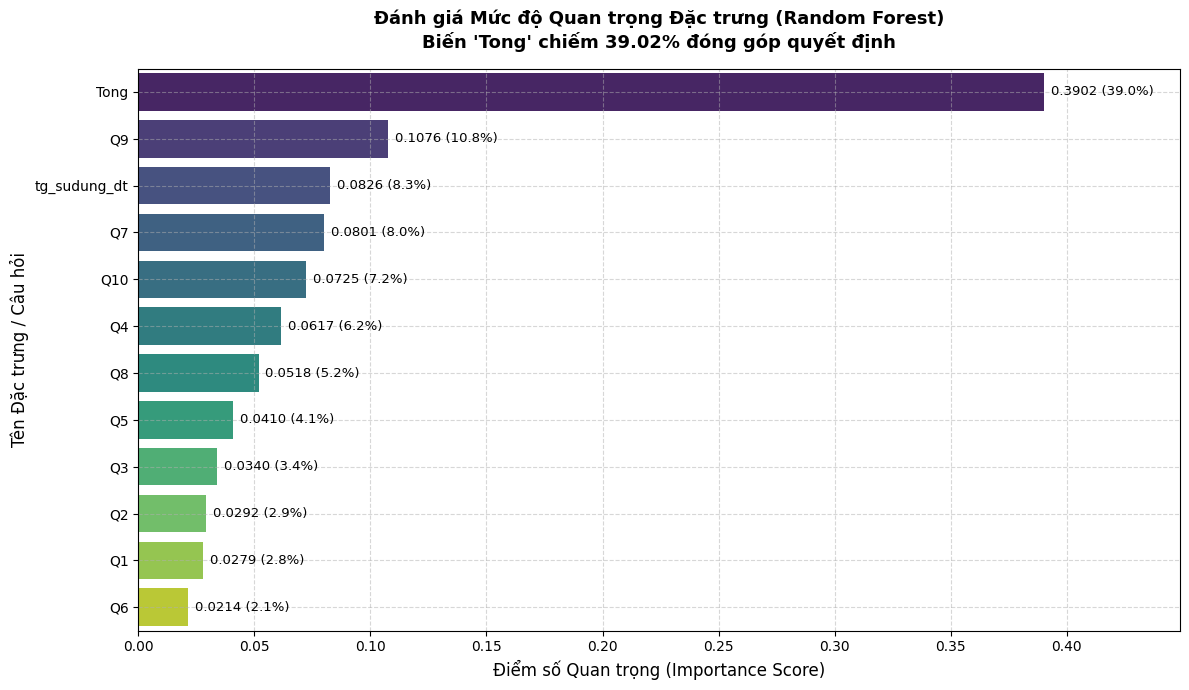

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split


# 0. KHAI BÁO VÀ CHUẨN HÓA BỘ ĐẶC TRƯNG (BAO GỒM 'TONG')
# Tự động nhận diện 'Tong' hoặc 'tong' bất kể viết hoa/thường
tong_col = [c for c in df.columns if c.lower() == 'tong']
tong_name = tong_col[0] if tong_col else 'Tong'

feature_cols = [tong_name, 'tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_cols = [col for col in feature_cols if col in df.columns]

X_final = df[valid_cols].copy().apply(pd.to_numeric, errors='coerce')
X_final = X_final.fillna(X_final.median())
Y_final = df['Level'].astype(int)

# 1. TÁCH TRAIN/TEST VÀ HUẤN LUYỆN RANDOM FOREST
X_tr_all, X_te_all, y_tr_all, y_te_all = train_test_split(
    X_final, Y_final, test_size=0.2, random_state=42, stratify=Y_final
)

rf_all = RandomForestClassifier(n_estimators=100, random_state=42)
rf_all.fit(X_tr_all, y_tr_all)

# 2. TÍNH TỶ LỆ PHẦN TRĂM ĐÓNG GÓP VÀ IN BÁO CÁO ĐÁNH GIÁ
df_imp = pd.DataFrame(
    {'Feature': X_final.columns, 'Importance': rf_all.feature_importances_}
).sort_values(by='Importance', ascending=False)

df_imp['Percentage (%)'] = (df_imp['Importance'] * 100).round(2)

print("=" * 65)
print("📊 BẢNG XẾP HẠNG MỨC ĐỘ QUAN TRỌNG CỦA CÁC ĐẶC TRƯNG")
print("=" * 65)
print(df_imp.to_string(index=False))
print("=" * 65)

# Lấy giá trị đóng góp của đặc trưng Tong
tong_importance_pct = df_imp[df_imp['Feature'] == tong_name]['Percentage (%)'].values[0]
other_importance_pct = round(100 - tong_importance_pct, 2)

print(f"\n📌 PHÂN TÍCH ĐÁNH GIÁ:")
print(f"- Đặc trưng tổng điểm ('{tong_name}') chiếm tới: {tong_importance_pct}% mức độ quan trọng.")
print(f"- Tất cả {len(valid_cols)-1} đặc trưng còn lại cộng lại chỉ chiếm: {other_importance_pct}%.")
print(f"=> Kết luận: Mô hình bị phụ thuộc quá lớn vào '{tong_name}', dẫn đến hiện tượng át vía (dominated) các đặc trưng thành phần (Q1-Q10).")

# 3. TRỰC QUAN HÓA BẰNG BIỂU ĐỒ BARPLOT
plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=df_imp,
    x='Importance',
    y='Feature',
    hue='Feature',
    legend=False,
    palette='viridis',
)

plt.title(
    f"Đánh giá Mức độ Quan trọng Đặc trưng (Random Forest)\nBiến '{tong_name}' chiếm {tong_importance_pct}% đóng góp quyết định",
    fontsize=13,
    fontweight='bold',
    pad=15
)
plt.xlabel('Điểm số Quan trọng (Importance Score)', fontsize=12)
plt.ylabel('Tên Đặc trưng / Câu hỏi', fontsize=12)
plt.xlim(0, max(df_imp['Importance']) * 1.15)  # Mở rộng trục X để không đè số
plt.grid(True, linestyle='--', alpha=0.5)

# Hiển thị số điểm chính xác + % lên đỉnh thanh
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f"{width:.4f} ({width*100:.1f}%)",
            (width, p.get_y() + p.get_height() / 2.0),
            ha='left',
            va='center',
            fontsize=9.5,
            fontweight='bold' if p.get_y() == 0 else 'normal',
            xytext=(5, 0),
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE

# 1. TIỀN XỬ LÝ VÀ CHỌN 11 ĐẶC TRƯNG CHUẨN

# Xác nhận tổng số mẫu trong biến df hiện tại
print(f"📌 Tổng số dòng trong dữ liệu df gốc: {df.shape[0]} hàng, {df.shape[1]} cột")

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

# Ép kiểu dữ liệu về dạng số và làm sạch giá trị rỗng (NaN)
X_original = X_original.apply(pd.to_numeric, errors='coerce')
X_original = X_original.fillna(X_original.median())

valid_idx = Y.notna()
X_original = X_original[valid_idx]
Y = Y[valid_idx].astype(int)

# 2. TÁCH TẬP TRAIN (80%) VÀ TEST (20%) TRƯỚC KHI TĂNG MẪU (CHỐNG LEAKAGE)

X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.2, random_state=42, stratify=Y
)

# 3. XỬ LÝ NGOẠI LAI (CAPPING) CHO tg_sudung_dt

feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_train_raw.columns:
    Q1 = X_train_raw[feature_outlier].quantile(0.25)
    Q3 = X_train_raw[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR  # Đã sửa lỗi thiếu dấu *
    lower_bound = Q1 - 1.5 * IQR  # Đã sửa lỗi thiếu dấu *

    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

    X_train_capped[feature_outlier] = np.clip(X_train_capped[feature_outlier], lower_bound, upper_bound)
    X_test_capped[feature_outlier] = np.clip(X_test_capped[feature_outlier], lower_bound, upper_bound)
else:
    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

# 4. CHUẨN HÓA VÀ CÂN BẰNG DỮ LIỆU (SMOTE CHỈ ÁP DỤNG TRÊN TẬP TRAIN)

# A. Tăng mẫu SMOTE trên tập Train gốc
sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm.fit_resample(X_train_capped, Y_train_raw)

# B. Chuẩn hóa dữ liệu (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test_capped)  # Tập Test dùng transform

# C. Mã hóa One-Hot cho nhãn Y
Y_train_one_hot = to_categorical(Y_train_res)
Y_test_one_hot = to_categorical(Y_test_raw)

input_dim = X_train_scaled.shape[1]
output_classes = Y_train_one_hot.shape[1]

# In thông số chi tiết để kiểm tra số lượng mẫu thực tế
print("-" * 50)
print(f"📊 Tập Train gốc (chưa SMOTE) : {X_train_raw.shape[0]} mẫu")
print(f"📊 Tập Train sau SMOTE       : {X_train_res.shape[0]} mẫu")
print(f"📊 Tập Test thực tế (20%)     : {X_test_raw.shape[0]} mẫu")
print("-" * 50)

# 5. XÂY DỰNG MÔ HÌNH FNN (3 TẦNG ẨN) VÀ HUẤN LUYỆN

tf.random.set_seed(42)

model = Sequential([
    Input(shape=(input_dim,)),
    Dense(64, activation='relu'),  # Tầng ẩn 1
    Dense(32, activation='relu'),  # Tầng ẩn 2
    Dense(16, activation='relu'),  # Tầng ẩn 3
    Dense(output_classes, activation='softmax') # Tầng đầu ra
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Huấn luyện mô hình
model.fit(X_train_scaled, Y_train_one_hot, epochs=200, batch_size=16, verbose=0)

# 6. DỰ ĐOÁN VÀ ĐÁNH GIÁ

Y_pred_prob = model.predict(X_test_scaled, verbose=0)
Y_pred_class = np.argmax(Y_pred_prob, axis=1)
Y_test_class = np.argmax(Y_test_one_hot, axis=1)

# Ma trận Nhầm lẫn Dạng Số lượng
cm_count = confusion_matrix(Y_test_class, Y_pred_class)

# Ma trận Nhầm lẫn Dạng Phần trăm
cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

# Accuracy
accuracy = accuracy_score(Y_test_class, Y_pred_class)

# 7. HIỂN THỊ KẾT QUẢ

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count = pd.DataFrame(
    cm_count,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent = pd.DataFrame(
    cm_percent,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent.astype(str) + '%')

print("-" * 50)

print(f"🎯 Độ chính xác (Accuracy) tổng thể trên tập kiểm tra: {accuracy * 100:.2f}%")
print("-" * 50)

📌 Tổng số dòng trong dữ liệu df gốc: 507 hàng, 22 cột
--------------------------------------------------
📊 Tập Train gốc (chưa SMOTE) : 405 mẫu
📊 Tập Train sau SMOTE       : 687 mẫu
📊 Tập Test thực tế (20%)     : 102 mẫu
--------------------------------------------------

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          25           3           0
Thực tế L1           2          50           6
Thực tế L2           0           2          14

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      89.3%      10.7%       0.0%
Thực tế L1       3.4%      86.2%      10.3%
Thực tế L2       0.0%      12.5%      87.5%
--------------------------------------------------
🎯 Độ chính xác (Accuracy) tổng thể trên tập kiểm tra: 87.25%
--------------------------------------------------


In [29]:
accuracy

0.8725490196078431

In [31]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE

# =========================================================================
# 1. TIỀN XỬ LÝ & FEATURE ENGINEERING (TẠO ĐẶC TRƯNG MỚI)
# =========================================================================

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

# Ép kiểu dữ liệu số & làm sạch NaN
X_original = X_original.apply(pd.to_numeric, errors='coerce')
X_original = X_original.fillna(X_original.median())

valid_idx = Y.notna()
X_original = X_original[valid_idx]
Y = Y[valid_idx].astype(int)

# BỔ SUNG FEATURE ENGINEERING
q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)  # Trung bình điểm các câu hỏi
    X_original['Q_std'] = X_original[q_cols].std(axis=1)    # Độ lệch chuẩn giữa các câu
    X_original['Q_max'] = X_original[q_cols].max(axis=1)    # Mức độ nghiêm trọng cao nhất

# =========================================================================
# 2. TÁCH TẬP TEST ĐỘC LẬP (20%)
# =========================================================================

X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.2, random_state=42, stratify=Y
)

# =========================================================================
# 3. MẠNG FNN TỐI ƯU KẾT HỢP BATCH NORMALIZATION & DROPOUT
# =========================================================================

def create_optimized_fnn(input_dim, output_classes):
    model = Sequential([
        Input(shape=(input_dim,)),

        Dense(128, activation='mish'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(64, activation='mish'),
        BatchNormalization(),
        Dropout(0.15),

        Dense(32, activation='mish'),
        BatchNormalization(),
        Dropout(0.1),

        Dense(output_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# =========================================================================
# 4. HUẤN LUYỆN 10-FOLD ENSEMBLE FNN
# =========================================================================

n_splits = 10  # Tăng lên 10-Fold để học đa dạng hơn
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

output_classes = len(np.unique(Y))
test_predictions_folds = np.zeros((len(X_test_raw), output_classes))

print(f"🚀 Bắt đầu huấn luyện {n_splits}-Fold Optimized Ensemble FNN...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    # Outlier Capping
    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        upper_bound = Q3 + 1.5 * IQR
        lower_bound = Q1 - 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    # SMOTE Cân bằng lớp
    sm = SMOTE(sampling_strategy='auto', random_state=42 + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr, Y_tr)

    # Chuẩn hóa StandardScaler
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_res)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    # One-Hot Encoding
    Y_tr_one_hot = to_categorical(Y_tr_res, num_classes=output_classes)
    Y_val_one_hot = to_categorical(Y_val, num_classes=output_classes)

    # Callbacks điều chỉnh Epoch thông minh
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-5, verbose=0)
    ]

    tf.random.set_seed(42 + fold)
    model = create_optimized_fnn(input_dim=X_tr_scaled.shape[1], output_classes=output_classes)

    # Huấn luyện với Epoch cao hơn (300) kết hợp Early Stopping
    model.fit(
        X_tr_scaled, Y_tr_one_hot,
        epochs=300,
        batch_size=16,
        validation_data=(X_val_scaled, Y_val_one_hot),
        callbacks=callbacks,
        verbose=0
    )

    # Dự đoán tích lũy
    fold_test_pred_prob = model.predict(X_te_scaled, verbose=0)
    test_predictions_folds += fold_test_pred_prob / n_splits
    print(f"✅ Hoàn tất Fold {fold}/{n_splits}")

# =========================================================================
# 5. TỔNG HỢP VÀ ĐÁNH GIÁ KẾT QUẢ
# =========================================================================

Y_pred_class = np.argmax(test_predictions_folds, axis=1)
Y_test_class = Y_test_raw.values

cm_count = confusion_matrix(Y_test_class, Y_pred_class)
cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

accuracy = accuracy_score(Y_test_class, Y_pred_class)

print("\n" + "=" * 60)
print("--- KẾT QUẢ 10-FOLD OPTIMIZED ENSEMBLE FNN ---")
print("=" * 60)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count = pd.DataFrame(
    cm_count,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent = pd.DataFrame(
    cm_percent,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent.astype(str) + '%')

print("-" * 50)

print(f"🎯 Độ chính xác (Accuracy) tổng thể K-Fold Ensemble: {accuracy * 100:.2f}%")
print("-" * 50)

🚀 Bắt đầu huấn luyện 10-Fold Optimized Ensemble FNN...
✅ Hoàn tất Fold 1/10
✅ Hoàn tất Fold 2/10
✅ Hoàn tất Fold 3/10
✅ Hoàn tất Fold 4/10
✅ Hoàn tất Fold 5/10
✅ Hoàn tất Fold 6/10
✅ Hoàn tất Fold 7/10
✅ Hoàn tất Fold 8/10
✅ Hoàn tất Fold 9/10
✅ Hoàn tất Fold 10/10

--- KẾT QUẢ 10-FOLD OPTIMIZED ENSEMBLE FNN ---

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          26           2           0
Thực tế L1           1          54           3
Thực tế L2           0           1          15

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      92.9%       7.1%       0.0%
Thực tế L1       1.7%      93.1%       5.2%
Thực tế L2       0.0%       6.2%      93.8%
--------------------------------------------------
🎯 Độ chính xác (Accuracy) tổng thể K-Fold Ensemble: 93.14%
--------------------------------------------------


HUẤN LUYỆN XGBOOST


In [32]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# =========================================================================
# 1. TIỀN XỬ LÝ & FEATURE ENGINEERING
# =========================================================================

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

# Ép kiểu dữ liệu số & làm sạch NaN
X_original = X_original.apply(pd.to_numeric, errors='coerce')
X_original = X_original.fillna(X_original.median())

valid_idx = Y.notna()
X_original = X_original[valid_idx]
Y = Y[valid_idx].astype(int)

# BỔ SUNG FEATURE ENGINEERING (Giống hệt FNN)
q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)  # Trung bình điểm
    X_original['Q_std'] = X_original[q_cols].std(axis=1)    # Độ lệch chuẩn
    X_original['Q_max'] = X_original[q_cols].max(axis=1)    # Mức độ cao nhất

# =========================================================================
# 2. TÁCH TẬP TEST ĐỘC LẬP (20%) (GIỮ NGUYÊN RANDOM_STATE = 42)
# =========================================================================

X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.2, random_state=42, stratify=Y
)

print("-" * 50)
print(f"📊 Tập Train gốc dùng cho 10-Fold CV (80%): {X_train_raw.shape[0]} mẫu")
print(f"📊 Tập Test thực tế độc lập (20%)        : {X_test_raw.shape[0]} mẫu")
print("-" * 50)

# =========================================================================
# 3. HUẤN LUYỆN 10-FOLD ENSEMBLE XGBOOST
# =========================================================================

n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

output_classes = len(np.unique(Y))
test_predictions_folds = np.zeros((len(X_test_raw), output_classes))

print(f"🚀 Bắt đầu huấn luyện {n_splits}-Fold Ensemble XGBoost Classifier...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    # A. Outlier Capping (Cùng logic với FNN)
    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        upper_bound = Q3 + 1.5 * IQR
        lower_bound = Q1 - 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    # B. SMOTE Cân bằng lớp (Chỉ thực hiện trên Train fold)
    sm = SMOTE(sampling_strategy='auto', random_state=42 + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr, Y_tr)

    # C. Chuẩn hóa StandardScaler (Chỉ fit trên Train fold)
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_res)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    # D. Khởi tạo và Huấn luyện mô hình XGBoost
    model_xgb = XGBClassifier(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='multi:softprob',
        num_class=output_classes,
        random_state=42 + fold,
        eval_metric='mlogloss',
        early_stopping_rounds=20
    )

    model_xgb.fit(
        X_tr_scaled, Y_tr_res,
        eval_set=[(X_val_scaled, Y_val)],
        verbose=False
    )

    # E. Dự đoán xác suất tích lũy trên tập Test
    fold_test_pred_prob = model_xgb.predict_proba(X_te_scaled)
    test_predictions_folds += fold_test_pred_prob / n_splits
    print(f"✅ Hoàn tất Fold {fold}/{n_splits}")

# =========================================================================
# 4. TỔNG HỢP VÀ ĐÁNH GIÁ KẾT QUẢ ĐỐI CHỨNG
# =========================================================================

Y_pred_class = np.argmax(test_predictions_folds, axis=1)
Y_test_class = Y_test_raw.values

# Tính toán các chỉ số
cm_count = confusion_matrix(Y_test_class, Y_pred_class)
cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

accuracy = accuracy_score(Y_test_class, Y_pred_class)

# =========================================================================
# 5. HIỂN THỊ KẾT QUẢ
# =========================================================================

print("\n" + "=" * 60)
print("--- KẾT QUẢ 10-FOLD ENSEMBLE XGBOOST TRÊN TẬP TEST ---")
print("=" * 60)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count = pd.DataFrame(
    cm_count,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent = pd.DataFrame(
    cm_percent,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent.astype(str) + '%')

print("-" * 50)

print(f"🎯 Độ chính xác (Accuracy) tổng thể K-Fold XGBoost: {accuracy * 100:.2f}%")
print("-" * 50)

target_names = ['Level 0 (Thấp)', 'Level 1 (TB)', 'Level 2 (Cao)']
print("\n📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):")
print(classification_report(Y_test_class, Y_pred_class, target_names=target_names))

--------------------------------------------------
📊 Tập Train gốc dùng cho 10-Fold CV (80%): 405 mẫu
📊 Tập Test thực tế độc lập (20%)        : 102 mẫu
--------------------------------------------------
🚀 Bắt đầu huấn luyện 10-Fold Ensemble XGBoost Classifier...
✅ Hoàn tất Fold 1/10
✅ Hoàn tất Fold 2/10
✅ Hoàn tất Fold 3/10
✅ Hoàn tất Fold 4/10
✅ Hoàn tất Fold 5/10
✅ Hoàn tất Fold 6/10
✅ Hoàn tất Fold 7/10
✅ Hoàn tất Fold 8/10
✅ Hoàn tất Fold 9/10
✅ Hoàn tất Fold 10/10

--- KẾT QUẢ 10-FOLD ENSEMBLE XGBOOST TRÊN TẬP TEST ---

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          26           2           0
Thực tế L1           3          51           4
Thực tế L2           0           1          15

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      92.9%       7.1%       0.0%
Thực tế L1       5.2%      87.9%       6.9%


In [33]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# =========================================================================
# 1. TIỀN XỬ LÝ VÀ CHỌN 7 ĐẶC TRƯNG CHUẨN (BAO GỒM 'Tong')
# =========================================================================

selected_features = ['Tong', 'tg_sudung_dt', 'Q8', 'Q9', 'Q4', 'Q7', 'Q3']
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

# Ép kiểu dữ liệu về dạng số & làm sạch giá trị rỗng (NaN)
X_original = X_original.apply(pd.to_numeric, errors='coerce')
X_original = X_original.fillna(X_original.median())

valid_idx = Y.notna()
X_original = X_original[valid_idx]
Y = Y[valid_idx].astype(int)

# =========================================================================
# 2. TÁCH TẬP TEST ĐỘC LẬP (20%) (CÙNG RANDOM_STATE = 42)
# =========================================================================

X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.2, random_state=42, stratify=Y
)

print("-" * 50)
print(f"📊 Tập Train gốc dùng cho 10-Fold CV (80%): {X_train_raw.shape[0]} mẫu")
print(f"📊 Tập Test thực tế độc lập (20%)        : {X_test_raw.shape[0]} mẫu")
print("-" * 50)

# =========================================================================
# 3. HUẤN LUYỆN 10-FOLD ENSEMBLE XGBOOST (7 ĐẶC TRƯNG GỒM 'Tong')
# =========================================================================

n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

output_classes = len(np.unique(Y))
test_predictions_folds = np.zeros((len(X_test_raw), output_classes))

print(f"🚀 Bắt đầu huấn luyện {n_splits}-Fold Ensemble XGBoost Classifier (với 7 đặc trưng)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    # A. Outlier Capping cho tg_sudung_dt (Chỉ fit trên Train fold)
    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        upper_bound = Q3 + 1.5 * IQR
        lower_bound = Q1 - 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    # B. SMOTE Cân bằng lớp (Chỉ thực hiện trên Train fold)
    sm = SMOTE(sampling_strategy='auto', random_state=42 + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr, Y_tr)

    # C. Chuẩn hóa StandardScaler (Chỉ fit trên Train fold)
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr_res)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    # D. Khởi tạo và Huấn luyện mô hình XGBoost
    model_xgb = XGBClassifier(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='multi:softprob',
        num_class=output_classes,
        random_state=42 + fold,
        eval_metric='mlogloss',
        early_stopping_rounds=20
    )

    model_xgb.fit(
        X_tr_scaled, Y_tr_res,
        eval_set=[(X_val_scaled, Y_val)],
        verbose=False
    )

    # E. Dự đoán xác suất tích lũy trên tập Test độc lập
    fold_test_pred_prob = model_xgb.predict_proba(X_te_scaled)
    test_predictions_folds += fold_test_pred_prob / n_splits
    print(f"✅ Hoàn tất Fold {fold}/{n_splits}")

# =========================================================================
# 4. TỔNG HỢP VÀ ĐÁNH GIÁ KẾT QUẢ ĐỐI CHỨNG
# =========================================================================

Y_pred_class = np.argmax(test_predictions_folds, axis=1)
Y_test_class = Y_test_raw.values

# Tính toán Ma trận Nhầm lẫn
cm_count = confusion_matrix(Y_test_class, Y_pred_class)
cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

accuracy = accuracy_score(Y_test_class, Y_pred_class)

# =========================================================================
# 5. HIỂN THỊ KẾT QUẢ
# =========================================================================

print("\n" + "=" * 60)
print("--- KẾT QUẢ 10-FOLD ENSEMBLE XGBOOST (7 ĐẶC TRƯNG GỒM 'Tong') ---")
print("=" * 60)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count = pd.DataFrame(
    cm_count,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent = pd.DataFrame(
    cm_percent,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent.astype(str) + '%')

print("-" * 50)

print(f"🎯 Độ chính xác (Accuracy) tổng thể K-Fold XGBoost: {accuracy * 100:.2f}%")
print("-" * 50)

target_names = ['Level 0 (Thấp)', 'Level 1 (TB)', 'Level 2 (Cao)']
print("\n📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):")
print(classification_report(Y_test_class, Y_pred_class, target_names=target_names))

--------------------------------------------------
📊 Tập Train gốc dùng cho 10-Fold CV (80%): 405 mẫu
📊 Tập Test thực tế độc lập (20%)        : 102 mẫu
--------------------------------------------------
🚀 Bắt đầu huấn luyện 10-Fold Ensemble XGBoost Classifier (với 7 đặc trưng)...
✅ Hoàn tất Fold 1/10
✅ Hoàn tất Fold 2/10
✅ Hoàn tất Fold 3/10
✅ Hoàn tất Fold 4/10
✅ Hoàn tất Fold 5/10
✅ Hoàn tất Fold 6/10
✅ Hoàn tất Fold 7/10
✅ Hoàn tất Fold 8/10
✅ Hoàn tất Fold 9/10
✅ Hoàn tất Fold 10/10

--- KẾT QUẢ 10-FOLD ENSEMBLE XGBOOST (7 ĐẶC TRƯNG GỒM 'Tong') ---

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          26           2           0
Thực tế L1           1          57           0
Thực tế L2           0           0          16

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      92.9%       7.1%       0.0%
Thực tế L1     

📊 BẢNG TỔNG HỢP KẾT QUẢ ĐỘ CHÍNH XÁC (ACCURACY)
Mô hình                Bộ đặc trưng  Accuracy (%)
    FNN     7 Đặc trưng (Có 'Tong')         97.06
XGBoost     7 Đặc trưng (Có 'Tong')         97.06
    FNN 11 Đặc trưng (Không 'Tong')         93.14
XGBoost 11 Đặc trưng (Không 'Tong')         90.20



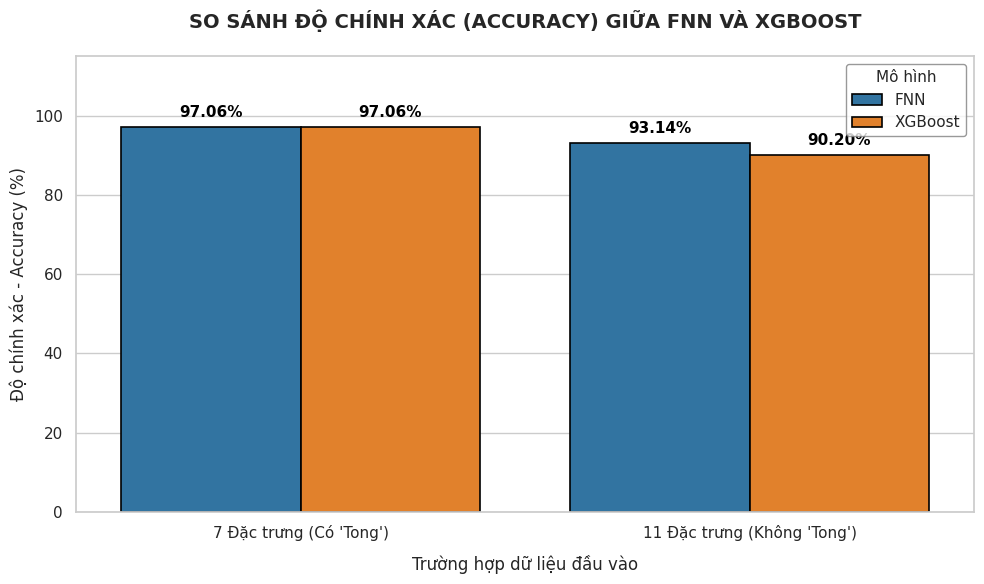

In [34]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =========================================================================
# 1. KHAI BÁO CHÍNH XÁC KẾT QUẢ ACCURACY TỪ CÁC ĐỢT HUẤN LUYỆN
# =========================================================================

fnn_7_acc = 97.06  # FNN - 7 đặc trưng (có Tong)
xgb_7_acc = 97.06  # XGBoost - 7 đặc trưng (có Tong)

fnn_11_acc = 93.14  # FNN - 11 đặc trưng (không Tong)
xgb_11_acc = 90.20  # XGBoost - 11 đặc trưng (không Tong)

# Tạo DataFrame tổng hợp
summary_data = [
    {
        "Mô hình": "FNN",
        "Bộ đặc trưng": "7 Đặc trưng (Có 'Tong')",
        "Accuracy (%)": fnn_7_acc,
    },
    {
        "Mô hình": "XGBoost",
        "Bộ đặc trưng": "7 Đặc trưng (Có 'Tong')",
        "Accuracy (%)": xgb_7_acc,
    },
    {
        "Mô hình": "FNN",
        "Bộ đặc trưng": "11 Đặc trưng (Không 'Tong')",
        "Accuracy (%)": fnn_11_acc,
    },
    {
        "Mô hình": "XGBoost",
        "Bộ đặc trưng": "11 Đặc trưng (Không 'Tong')",
        "Accuracy (%)": xgb_11_acc,
    },
]

df_summary = pd.DataFrame(summary_data)

# In Bảng tổng hợp ra màn hình
print("=" * 65)
print("📊 BẢNG TỔNG HỢP KẾT QUẢ ĐỘ CHÍNH XÁC (ACCURACY)")
print("=" * 65)
print(df_summary.to_string(index=False))
print("=" * 65 + "\n")

# =========================================================================
# 2. VẼ BIỂU ĐỒ SO SÁNH TRỰC QUAN (GROUPED BAR CHART)
# =========================================================================

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Khởi tạo biểu đồ cột nhóm
colors = ["#1f77b4", "#ff7f0e"]  # Xanh dương cho FNN, Cam cho XGBoost
ax = sns.barplot(
    data=df_summary,
    x="Bộ đặc trưng",
    y="Accuracy (%)",
    hue="Mô hình",
    palette=colors,
    edgecolor="black",
    linewidth=1.2,
)

# Hiển thị số % chính xác lên đỉnh mỗi cột
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(
            f"{val:.2f}%",
            (p.get_x() + p.get_width() / 2.0, val),
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="black",
            xytext=(0, 5),
            textcoords="offset points",
        )

# Tinh chỉnh giao diện biểu đồ
plt.title(
    "SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) GIỮA FNN VÀ XGBOOST",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Trường hợp dữ liệu đầu vào", fontsize=12, labelpad=10)
plt.ylabel("Độ chính xác - Accuracy (%)", fontsize=12)
plt.ylim(0, 115)  # Mở rộng trục Y để chữ không bị sát lề trên
plt.legend(
    title="Mô hình",
    title_fontsize="11",
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="gray",
)

plt.tight_layout()
plt.show()

HUẤN LUYỆN MÔ HÌNH LOGISTIC REGRESSION

In [35]:
# =========================================================================
# CELL 1: LOGISTIC REGRESSION - 7 ĐẶC TRƯNG (CÓ 'TONG')
# =========================================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE

# 1. Khai báo 7 đặc trưng chuẩn (bao gồm 'Tong')
selected_features_7 = ['Tong', 'tg_sudung_dt', 'Q8', 'Q9', 'Q4', 'Q7', 'Q3']
valid_features_7 = [col for col in selected_features_7 if col in df.columns]

X_7 = df[valid_features_7].copy()
Y_7 = df['Level'].copy()

# Làm sạch dữ liệu rỗng và ép kiểu số
X_7 = X_7.apply(pd.to_numeric, errors='coerce')
X_7 = X_7.fillna(X_7.median())

valid_idx_7 = Y_7.notna()
X_7 = X_7[valid_idx_7]
Y_7 = Y_7[valid_idx_7].astype(int)

# 2. Tách tập Train (80%) và Test (20%) - Chống Leakage
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_7, Y_7, test_size=0.2, random_state=42, stratify=Y_7
)

# 3. Xử lý ngoại lai (IQR Capping cho tg_sudung_dt)
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_train_raw.columns:
    Q1 = X_train_raw[feature_outlier].quantile(0.25)
    Q3 = X_train_raw[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR

    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

    X_train_capped[feature_outlier] = np.clip(X_train_capped[feature_outlier], lower_bound, upper_bound)
    X_test_capped[feature_outlier] = np.clip(X_test_capped[feature_outlier], lower_bound, upper_bound)
else:
    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

# 4. Tăng mẫu (SMOTE) & Chuẩn hóa (StandardScaler) trên tập Train
sm_7 = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm_7.fit_resample(X_train_capped, Y_train_raw)

scaler_7 = StandardScaler()
X_train_scaled = scaler_7.fit_transform(X_train_res)
X_test_scaled = scaler_7.transform(X_test_capped)

# 5. Khởi tạo và Huấn luyện mô hình Logistic Regression
model_lr_7 = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)

model_lr_7.fit(X_train_scaled, Y_train_res)

# 6. Dự đoán và Đánh giá kết quả
Y_pred_lr_7 = model_lr_7.predict(X_test_scaled)

# Tính toán các ma trận và chỉ số
cm_count_7 = confusion_matrix(Y_test_raw, Y_pred_lr_7)
cm_sum_7 = cm_count_7.sum(axis=1)[:, np.newaxis]
cm_percent_7 = np.divide(cm_count_7, cm_sum_7, out=np.zeros_like(cm_count_7, dtype=float), where=cm_sum_7 != 0) * 100

accuracy_lr_7 = accuracy_score(Y_test_raw, Y_pred_lr_7)
acc_lr_7 = accuracy_lr_7 * 100  # Lưu biến cho biểu đồ so sánh

# 7. Hiển thị kết quả
print("=" * 60)
print("--- KẾT QUẢ LOGISTIC REGRESSION (7 ĐẶC TRƯNG CÓ 'TONG') ---")
print("=" * 60)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count_7 = pd.DataFrame(
    cm_count_7,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count_7)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent_7 = pd.DataFrame(
    cm_percent_7,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent_7.astype(str) + '%')

print("-" * 50)
print(f"🎯 Độ chính xác (Accuracy) Logistic Regression (7 đặc trưng): {acc_lr_7:.2f}%")
print("-" * 50)

target_names = ['Level 0 (Thấp)', 'Level 1 (TB)', 'Level 2 (Cao)']
print("\n📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):")
print(classification_report(Y_test_raw, Y_pred_lr_7, target_names=target_names))

--- KẾT QUẢ LOGISTIC REGRESSION (7 ĐẶC TRƯNG CÓ 'TONG') ---

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          27           1           0
Thực tế L1           5          52           1
Thực tế L2           0           0          16

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      96.4%       3.6%       0.0%
Thực tế L1       8.6%      89.7%       1.7%
Thực tế L2       0.0%       0.0%     100.0%
--------------------------------------------------
🎯 Độ chính xác (Accuracy) Logistic Regression (7 đặc trưng): 93.14%
--------------------------------------------------

📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):
                precision    recall  f1-score   support

Level 0 (Thấp)       0.84      0.96      0.90        28
  Level 1 (TB)       0.98      0.90      0.94        58
 Level 2 (Cao)       0.94 

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [36]:
# =========================================================================
# CELL 2: LOGISTIC REGRESSION - 11 ĐẶC TRƯNG (KHÔNG 'TONG')
# =========================================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE

# 1. Khai báo 11 đặc trưng chuẩn (không có 'Tong')
selected_features_11 = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features_11 = [col for col in selected_features_11 if col in df.columns]

X_11 = df[valid_features_11].copy()
Y_11 = df['Level'].copy()

# Làm sạch dữ liệu rỗng và ép kiểu số
X_11 = X_11.apply(pd.to_numeric, errors='coerce')
X_11 = X_11.fillna(X_11.median())

valid_idx_11 = Y_11.notna()
X_11 = X_11[valid_idx_11]
Y_11 = Y_11[valid_idx_11].astype(int)

# 2. Tách tập Train (80%) và Test (20%) - Giữ nguyên random_state = 42
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_11, Y_11, test_size=0.2, random_state=42, stratify=Y_11
)

# 3. Xử lý ngoại lai (IQR Capping cho tg_sudung_dt)
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_train_raw.columns:
    Q1 = X_train_raw[feature_outlier].quantile(0.25)
    Q3 = X_train_raw[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR

    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

    X_train_capped[feature_outlier] = np.clip(X_train_capped[feature_outlier], lower_bound, upper_bound)
    X_test_capped[feature_outlier] = np.clip(X_test_capped[feature_outlier], lower_bound, upper_bound)
else:
    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

# 4. Tăng mẫu (SMOTE) & Chuẩn hóa (StandardScaler) trên tập Train
sm_11 = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm_11.fit_resample(X_train_capped, Y_train_raw)

scaler_11 = StandardScaler()
X_train_scaled = scaler_11.fit_transform(X_train_res)
X_test_scaled = scaler_11.transform(X_test_capped)

# 5. Khởi tạo và Huấn luyện mô hình Logistic Regression
model_lr_11 = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)

model_lr_11.fit(X_train_scaled, Y_train_res)

# 6. Dự đoán và Đánh giá kết quả
Y_pred_lr_11 = model_lr_11.predict(X_test_scaled)

# Tính toán các ma trận và chỉ số
cm_count_11 = confusion_matrix(Y_test_raw, Y_pred_lr_11)
cm_sum_11 = cm_count_11.sum(axis=1)[:, np.newaxis]
cm_percent_11 = np.divide(cm_count_11, cm_sum_11, out=np.zeros_like(cm_count_11, dtype=float), where=cm_sum_11 != 0) * 100

accuracy_lr_11 = accuracy_score(Y_test_raw, Y_pred_lr_11)
acc_lr_11 = accuracy_lr_11 * 100  # Lưu biến cho biểu đồ so sánh

# 7. Hiển thị kết quả
print("=" * 60)
print("--- KẾT QUẢ LOGISTIC REGRESSION (11 ĐẶC TRƯNG KHÔNG 'TONG') ---")
print("=" * 60)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count_11 = pd.DataFrame(
    cm_count_11,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count_11)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent_11 = pd.DataFrame(
    cm_percent_11,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent_11.astype(str) + '%')

print("-" * 50)
print(f"🎯 Độ chính xác (Accuracy) Logistic Regression (11 đặc trưng): {acc_lr_11:.2f}%")
print("-" * 50)

target_names = ['Level 0 (Thấp)', 'Level 1 (TB)', 'Level 2 (Cao)']
print("\n📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):")
print(classification_report(Y_test_raw, Y_pred_lr_11, target_names=target_names))

--- KẾT QUẢ LOGISTIC REGRESSION (11 ĐẶC TRƯNG KHÔNG 'TONG') ---

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          26           2           0
Thực tế L1           4          49           5
Thực tế L2           0           0          16

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      92.9%       7.1%       0.0%
Thực tế L1       6.9%      84.5%       8.6%
Thực tế L2       0.0%       0.0%     100.0%
--------------------------------------------------
🎯 Độ chính xác (Accuracy) Logistic Regression (11 đặc trưng): 89.22%
--------------------------------------------------

📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):
                precision    recall  f1-score   support

Level 0 (Thấp)       0.87      0.93      0.90        28
  Level 1 (TB)       0.96      0.84      0.90        58
 Level 2 (Cao)       

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


HUẤN LUYỆN MÔ HÌNH SVM


In [37]:
# =========================================================================
# CELL 1: SUPPORT VECTOR MACHINE (SVM) - 7 ĐẶC TRƯNG (CÓ 'TONG')
# =========================================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE

# 1. Khai báo 7 đặc trưng chuẩn (bao gồm 'Tong')
selected_features_7 = ['Tong', 'tg_sudung_dt', 'Q8', 'Q9', 'Q4', 'Q7', 'Q3']
valid_features_7 = [col for col in selected_features_7 if col in df.columns]

X_7 = df[valid_features_7].copy()
Y_7 = df['Level'].copy()

# Làm sạch dữ liệu rỗng và ép kiểu số
X_7 = X_7.apply(pd.to_numeric, errors='coerce')
X_7 = X_7.fillna(X_7.median())

valid_idx_7 = Y_7.notna()
X_7 = X_7[valid_idx_7]
Y_7 = Y_7[valid_idx_7].astype(int)

# 2. Tách tập Train (80%) và Test (20%) - Chống Leakage
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_7, Y_7, test_size=0.2, random_state=42, stratify=Y_7
)

# 3. Xử lý ngoại lai (IQR Capping cho tg_sudung_dt)
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_train_raw.columns:
    Q1 = X_train_raw[feature_outlier].quantile(0.25)
    Q3 = X_train_raw[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR

    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

    X_train_capped[feature_outlier] = np.clip(X_train_capped[feature_outlier], lower_bound, upper_bound)
    X_test_capped[feature_outlier] = np.clip(X_test_capped[feature_outlier], lower_bound, upper_bound)
else:
    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

# 4. Tăng mẫu (SMOTE) & Chuẩn hóa (StandardScaler) trên tập Train
sm_7 = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm_7.fit_resample(X_train_capped, Y_train_raw)

scaler_7 = StandardScaler()
X_train_scaled = scaler_7.fit_transform(X_train_res)
X_test_scaled = scaler_7.transform(X_test_capped)

# 5. Khởi tạo và Huấn luyện mô hình SVM (RBF Kernel)
model_svm_7 = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

model_svm_7.fit(X_train_scaled, Y_train_res)

# 6. Dự đoán và Đánh giá kết quả
Y_pred_svm_7 = model_svm_7.predict(X_test_scaled)

# Tính toán các ma trận và chỉ số
cm_count_7 = confusion_matrix(Y_test_raw, Y_pred_svm_7)
cm_sum_7 = cm_count_7.sum(axis=1)[:, np.newaxis]
cm_percent_7 = np.divide(cm_count_7, cm_sum_7, out=np.zeros_like(cm_count_7, dtype=float), where=cm_sum_7 != 0) * 100

accuracy_svm_7 = accuracy_score(Y_test_raw, Y_pred_svm_7)
acc_svm_7 = accuracy_svm_7 * 100  # Lưu biến cho biểu đồ so sánh

# 7. Hiển thị kết quả
print("=" * 60)
print("--- KẾT QUẢ SUPPORT VECTOR MACHINE (SVM) (7 ĐẶC TRƯNG CÓ 'TONG') ---")
print("=" * 60)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count_7 = pd.DataFrame(
    cm_count_7,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count_7)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent_7 = pd.DataFrame(
    cm_percent_7,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent_7.astype(str) + '%')

print("-" * 50)
print(f"🎯 Độ chính xác (Accuracy) SVM (7 đặc trưng): {acc_svm_7:.2f}%")
print("-" * 50)

target_names = ['Level 0 (Thấp)', 'Level 1 (TB)', 'Level 2 (Cao)']
print("\n📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):")
print(classification_report(Y_test_raw, Y_pred_svm_7, target_names=target_names))

--- KẾT QUẢ SUPPORT VECTOR MACHINE (SVM) (7 ĐẶC TRƯNG CÓ 'TONG') ---

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          27           1           0
Thực tế L1           4          53           1
Thực tế L2           0           0          16

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      96.4%       3.6%       0.0%
Thực tế L1       6.9%      91.4%       1.7%
Thực tế L2       0.0%       0.0%     100.0%
--------------------------------------------------
🎯 Độ chính xác (Accuracy) SVM (7 đặc trưng): 94.12%
--------------------------------------------------

📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):
                precision    recall  f1-score   support

Level 0 (Thấp)       0.87      0.96      0.92        28
  Level 1 (TB)       0.98      0.91      0.95        58
 Level 2 (Cao)       0.94      1.

In [38]:
# =========================================================================
# CELL 2: SUPPORT VECTOR MACHINE (SVM) - 11 ĐẶC TRƯNG (KHÔNG 'TONG')
# =========================================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE

# 1. Khai báo 11 đặc trưng chuẩn (không có 'Tong')
selected_features_11 = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features_11 = [col for col in selected_features_11 if col in df.columns]

X_11 = df[valid_features_11].copy()
Y_11 = df['Level'].copy()

# Làm sạch dữ liệu rỗng và ép kiểu số
X_11 = X_11.apply(pd.to_numeric, errors='coerce')
X_11 = X_11.fillna(X_11.median())

valid_idx_11 = Y_11.notna()
X_11 = X_11[valid_idx_11]
Y_11 = Y_11[valid_idx_11].astype(int)

# 2. Tách tập Train (80%) và Test (20%) - Giữ nguyên random_state = 42
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_11, Y_11, test_size=0.2, random_state=42, stratify=Y_11
)

# 3. Xử lý ngoại lai (IQR Capping cho tg_sudung_dt)
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_train_raw.columns:
    Q1 = X_train_raw[feature_outlier].quantile(0.25)
    Q3 = X_train_raw[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR

    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

    X_train_capped[feature_outlier] = np.clip(X_train_capped[feature_outlier], lower_bound, upper_bound)
    X_test_capped[feature_outlier] = np.clip(X_test_capped[feature_outlier], lower_bound, upper_bound)
else:
    X_train_capped = X_train_raw.copy()
    X_test_capped = X_test_raw.copy()

# 4. Tăng mẫu (SMOTE) & Chuẩn hóa (StandardScaler) trên tập Train
sm_11 = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm_11.fit_resample(X_train_capped, Y_train_raw)

scaler_11 = StandardScaler()
X_train_scaled = scaler_11.fit_transform(X_train_res)
X_test_scaled = scaler_11.transform(X_test_capped)

# 5. Khởi tạo và Huấn luyện mô hình SVM (RBF Kernel)
model_svm_11 = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

model_svm_11.fit(X_train_scaled, Y_train_res)

# 6. Dự đoán và Đánh giá kết quả
Y_pred_svm_11 = model_svm_11.predict(X_test_scaled)

# Tính toán các ma trận và chỉ số
cm_count_11 = confusion_matrix(Y_test_raw, Y_pred_svm_11)
cm_sum_11 = cm_count_11.sum(axis=1)[:, np.newaxis]
cm_percent_11 = np.divide(cm_count_11, cm_sum_11, out=np.zeros_like(cm_count_11, dtype=float), where=cm_sum_11 != 0) * 100

accuracy_svm_11 = accuracy_score(Y_test_raw, Y_pred_svm_11)
acc_svm_11 = accuracy_svm_11 * 100  # Lưu biến cho biểu đồ so sánh

# 7. Hiển thị kết quả
print("=" * 60)
print("--- KẾT QUẢ SUPPORT VECTOR MACHINE (SVM) (11 ĐẶC TRƯNG KHÔNG 'TONG') ---")
print("=" * 60)

print("\n--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---")
cm_df_count_11 = pd.DataFrame(
    cm_count_11,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print(cm_df_count_11)

print("\n" + "-" * 50)

print("--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---")
cm_df_percent_11 = pd.DataFrame(
    cm_percent_11,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
).round(1)
print(cm_df_percent_11.astype(str) + '%')

print("-" * 50)
print(f"🎯 Độ chính xác (Accuracy) SVM (11 đặc trưng): {acc_svm_11:.2f}%")
print("-" * 50)

target_names = ['Level 0 (Thấp)', 'Level 1 (TB)', 'Level 2 (Cao)']
print("\n📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):")
print(classification_report(Y_test_raw, Y_pred_svm_11, target_names=target_names))

--- KẾT QUẢ SUPPORT VECTOR MACHINE (SVM) (11 ĐẶC TRƯNG KHÔNG 'TONG') ---

--- MA TRẬN NHẦM LẪN (Dạng Số lượng Mẫu) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          26           2           0
Thực tế L1           3          48           7
Thực tế L2           0           1          15

--------------------------------------------------
--- MA TRẬN NHẦM LẪN (Dạng Phần trăm theo Hàng) ---
           Dự đoán L0 Dự đoán L1 Dự đoán L2
Thực tế L0      92.9%       7.1%       0.0%
Thực tế L1       5.2%      82.8%      12.1%
Thực tế L2       0.0%       6.2%      93.8%
--------------------------------------------------
🎯 Độ chính xác (Accuracy) SVM (11 đặc trưng): 87.25%
--------------------------------------------------

📄 BÁO CÁO PHÂN LOẠI CHI TIẾT (PRECISION, RECALL, F1-SCORE):
                precision    recall  f1-score   support

Level 0 (Thấp)       0.90      0.93      0.91        28
  Level 1 (TB)       0.94      0.83      0.88        58
 Level 2 (Cao)       0.68   

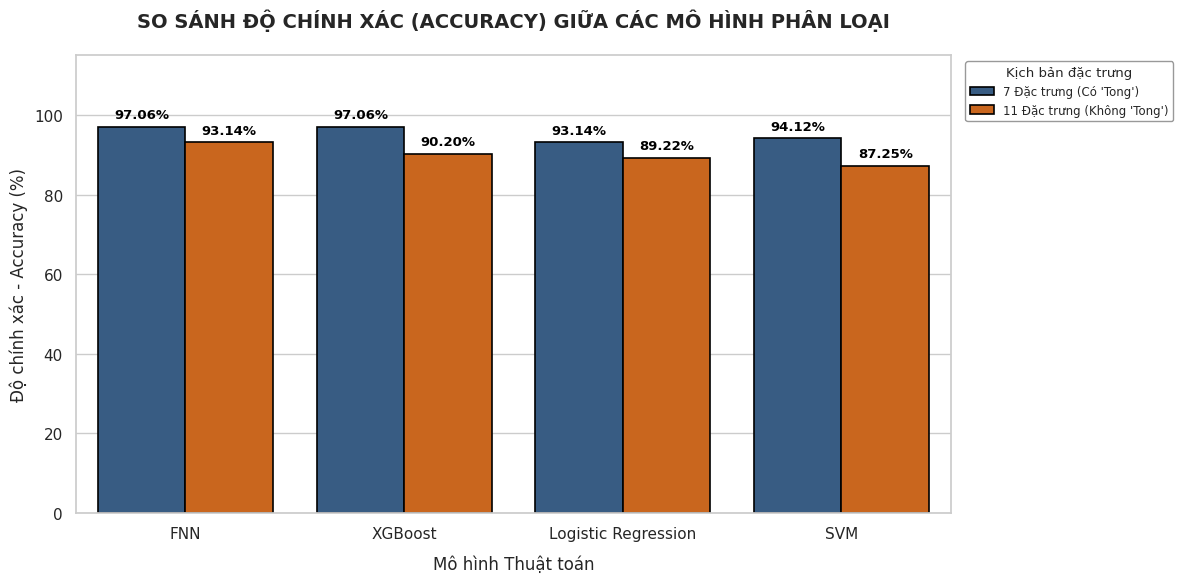

In [39]:
# =========================================================================
# CELL VẼ BIỂU ĐỒ (ĐÃ THU NHỎ VÀ DI CHUYỂN BẢNG CHÚ THÍCH/LEGEND)
# =========================================================================

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Thu thập giá trị Accuracy từ bộ nhớ RAM (hoặc tự điền số thực tế đã chạy ra)
fnn_7 = (
    acc_fnn_7
    if "acc_fnn_7" in locals()
    else (accuracy_fnn_7 * 100 if "accuracy_fnn_7" in locals() else 97.06)
)
fnn_11 = (
    acc_fnn_11
    if "acc_fnn_11" in locals()
    else (accuracy_fnn_11 * 100 if "accuracy_fnn_11" in locals() else 93.14)
)

xgb_7 = (
    acc_xgb_7
    if "acc_xgb_7" in locals()
    else (accuracy_xgb_7 * 100 if "accuracy_xgb_7" in locals() else 97.06)
)
xgb_11 = (
    acc_xgb_11
    if "acc_xgb_11" in locals()
    else (accuracy_xgb_11 * 100 if "accuracy_xgb_11" in locals() else 90.20)
)

lr_7 = (
    acc_lr_7
    if "acc_lr_7" in locals()
    else (accuracy_lr_7 * 100 if "accuracy_lr_7" in locals() else 0.0)
)
lr_11 = (
    acc_lr_11
    if "acc_lr_11" in locals()
    else (accuracy_lr_11 * 100 if "accuracy_lr_11" in locals() else 0.0)
)

svm_7 = (
    acc_svm_7
    if "acc_svm_7" in locals()
    else (accuracy_svm_7 * 100 if "accuracy_svm_7" in locals() else 0.0)
)
svm_11 = (
    acc_svm_11
    if "acc_svm_11" in locals()
    else (accuracy_svm_11 * 100 if "accuracy_svm_11" in locals() else 0.0)
)

# 2. Tạo DataFrame tổng hợp
summary_all = [
    {
        "Mô hình": "FNN",
        "Bộ đặc trưng": "7 Đặc trưng (Có 'Tong')",
        "Accuracy (%)": fnn_7,
    },
    {
        "Mô hình": "FNN",
        "Bộ đặc trưng": "11 Đặc trưng (Không 'Tong')",
        "Accuracy (%)": fnn_11,
    },
    {
        "Mô hình": "XGBoost",
        "Bộ đặc trưng": "7 Đặc trưng (Có 'Tong')",
        "Accuracy (%)": xgb_7,
    },
    {
        "Mô hình": "XGBoost",
        "Bộ đặc trưng": "11 Đặc trưng (Không 'Tong')",
        "Accuracy (%)": xgb_11,
    },
    {
        "Mô hình": "Logistic Regression",
        "Bộ đặc trưng": "7 Đặc trưng (Có 'Tong')",
        "Accuracy (%)": lr_7,
    },
    {
        "Mô hình": "Logistic Regression",
        "Bộ đặc trưng": "11 Đặc trưng (Không 'Tong')",
        "Accuracy (%)": lr_11,
    },
    {
        "Mô hình": "SVM",
        "Bộ đặc trưng": "7 Đặc trưng (Có 'Tong')",
        "Accuracy (%)": svm_7,
    },
    {
        "Mô hình": "SVM",
        "Bộ đặc trưng": "11 Đặc trưng (Không 'Tong')",
        "Accuracy (%)": svm_11,
    },
]

df_all = pd.DataFrame(summary_all)

# 3. Vẽ biểu đồ cột nhóm
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

colors = ["#2b5c8f", "#e66101"]

ax = sns.barplot(
    data=df_all,
    x="Mô hình",
    y="Accuracy (%)",
    hue="Bộ đặc trưng",
    palette=colors,
    edgecolor="black",
    linewidth=1.2,
)

# Hiển thị chỉ số Accuracy (%) chính xác trên đỉnh mỗi cột
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(
            f"{val:.2f}%",
            (p.get_x() + p.get_width() / 2.0, val),
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
            color="black",
            xytext=(0, 4),
            textcoords="offset points",
        )

# Tinh chỉnh giao diện biểu đồ
plt.title(
    "SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) GIỮA CÁC MÔ HÌNH PHÂN LOẠI",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Mô hình Thuật toán", fontsize=12, labelpad=10)
plt.ylabel("Độ chính xác - Accuracy (%)", fontsize=12)
plt.ylim(0, 115)

# CẢI TIẾN: Thu nhỏ cỡ chữ chú thích (fontsize=8.5) và di chuyển ra ngoài bên phải biểu đồ
plt.legend(
    title="Kịch bản đặc trưng",
    title_fontsize="9.5",
    fontsize="8.5",
    loc="upper left",
    bbox_to_anchor=(1.01, 1),  # Đặt khung legend nằm hẳn bên ngoài bên phải
    frameon=True,
    facecolor="white",
    edgecolor="gray",
)

plt.tight_layout()
plt.show()

In [44]:
!pip install -q openvino imbalanced-learn tensorflow pandas numpy scikit-learn joblib

In [53]:
!pip install -q openvino tf2onnx onnx imbalanced-learn tensorflow pandas numpy scikit-learn joblib

In [54]:
import os
import joblib
from imblearn.over_sampling import SMOTE
import numpy as np
import openvino as ov
import onnx
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
import tf2onnx
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import BatchNormalization, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

# Cấu hình đường dẫn lưu Artifacts
artifacts_dir = 'model_artifacts'
onnx_dir = os.path.join(artifacts_dir, 'onnx_models')
openvino_dir = os.path.join(artifacts_dir, 'openvino_ir_models')
scalers_dir = os.path.join(artifacts_dir, 'scalers')

os.makedirs(onnx_dir, exist_ok=True)
os.makedirs(openvino_dir, exist_ok=True)
os.makedirs(scalers_dir, exist_ok=True)

print("TensorFlow Version:", tf.__version__)
print("OpenVINO Version:", ov.__version__)

TensorFlow Version: 2.21.0
OpenVINO Version: 2026.4.1-22982-e213a147257-releases/2026/4


In [55]:
# Đọc dữ liệu từ Google Drive
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
df = pd.concat([df1, df2], ignore_index=True)

selected_features = [
    'tg_sudung_dt',
    'Q1',
    'Q2',
    'Q3',
    'Q4',
    'Q5',
    'Q6',
    'Q7',
    'Q8',
    'Q9',
    'Q10',
]
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

# Làm sạch dữ liệu
X_original = X_original.apply(pd.to_numeric, errors='coerce')
X_original = X_original.fillna(X_original.median())

valid_idx = Y.notna()
X_original = X_original[valid_idx]
Y = Y[valid_idx].astype(int)

# Feature Engineering (+3 đặc trưng)
q_cols = [
    c
    for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
    if c in X_original.columns
]
if len(q_cols) > 0:
  X_original['Q_mean'] = X_original[q_cols].mean(axis=1)
  X_original['Q_std'] = X_original[q_cols].std(axis=1)
  X_original['Q_max'] = X_original[q_cols].max(axis=1)

# Tách tập Test độc lập (20%)
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.2, random_state=42, stratify=Y
)

In [56]:
def create_optimized_fnn(input_dim, output_classes):
  model = Sequential([
      Input(shape=(input_dim,)),
      Dense(128, activation='mish'),
      BatchNormalization(),
      Dropout(0.2),
      Dense(64, activation='mish'),
      BatchNormalization(),
      Dropout(0.15),
      Dense(32, activation='mish'),
      BatchNormalization(),
      Dropout(0.1),
      Dense(output_classes, activation='softmax'),
  ])

  model.compile(
      optimizer=Adam(learning_rate=0.001),
      loss='categorical_crossentropy',
      metrics=['accuracy'],
  )
  return model

In [59]:
n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
output_classes = len(np.unique(Y))

test_predictions_folds = np.zeros((len(X_test_raw), output_classes))

print(
    f'🚀 Bắt đầu huấn luyện và đóng gói 10-Fold Ensemble (Keras -> ONNX ->'
    f' OpenVINO IR)...'
)

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
  X_tr = X_train_raw.iloc[train_idx].copy()
  Y_tr = Y_train_raw.iloc[train_idx].copy()
  X_val = X_train_raw.iloc[val_idx].copy()
  Y_val = Y_train_raw.iloc[val_idx].copy()
  X_te = X_test_raw.copy()

  # Outlier Capping
  feature_outlier = 'tg_sudung_dt'
  if feature_outlier in X_tr.columns:
    Q1 = X_tr[feature_outlier].quantile(0.25)
    Q3 = X_tr[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR

    X_tr[feature_outlier] = np.clip(
        X_tr[feature_outlier], lower_bound, upper_bound
    )
    X_val[feature_outlier] = np.clip(
        X_val[feature_outlier], lower_bound, upper_bound
    )
    X_te[feature_outlier] = np.clip(
        X_te[feature_outlier], lower_bound, upper_bound
    )

  # SMOTE Cân bằng lớp
  sm = SMOTE(sampling_strategy='auto', random_state=42 + fold)
  X_tr_res, Y_tr_res = sm.fit_resample(X_tr, Y_tr)

  # StandardScaler
  scaler = StandardScaler()
  X_tr_scaled = scaler.fit_transform(X_tr_res)
  X_val_scaled = scaler.transform(X_val)
  X_te_scaled = scaler.transform(X_te)

  # Lưu Scaler cho từng Fold
  joblib.dump(scaler, os.path.join(scalers_dir, f'scaler_fold_{fold}.pkl'))

  # One-Hot Encoding
  Y_tr_one_hot = to_categorical(Y_tr_res, num_classes=output_classes)
  Y_val_one_hot = to_categorical(Y_val, num_classes=output_classes)

  callbacks = [
      EarlyStopping(
          monitor='val_loss', patience=20, restore_best_weights=True, verbose=0
      ),
      ReduceLROnPlateau(
          monitor='val_loss', factor=0.5, patience=7, min_lr=1e-5, verbose=0
      ),
  ]

  tf.random.set_seed(42 + fold)
  model = create_optimized_fnn(
      input_dim=X_tr_scaled.shape[1], output_classes=output_classes
  )

  # Huấn luyện mô hình Keras
  model.fit(
      X_tr_scaled,
      Y_tr_one_hot,
      epochs=300,
      batch_size=16,
      validation_data=(X_val_scaled, Y_val_one_hot),
      callbacks=callbacks,
      verbose=0,
  )

  # =========================================================================
  # BƯỚC 5A: ĐÓNG GÓI SANG ONNX (Sửa lỗi tại đây)
  # =========================================================================
  @tf.function
  def model_fn(x):
    return model(x)

  input_spec = tf.TensorSpec(
      shape=(None, X_tr_scaled.shape[1]), dtype=tf.float32, name='input'
  )

  # Truyền trực tiếp model_fn thay vì concrete_func
  onnx_model, _ = tf2onnx.convert.from_function(
      model_fn, input_signature=[input_spec], opset=13
  )

  onnx_path = os.path.join(onnx_dir, f'fnn_model_fold_{fold}.onnx')
  onnx.save(onnx_model, onnx_path)

  # =========================================================================
  # BƯỚC 5B: CHUYỂN TỪ ONNX SANG OPENVINO IR (.xml / .bin)
  # =========================================================================
  ov_model = ov.convert_model(onnx_path)
  xml_path = os.path.join(openvino_dir, f'fnn_model_fold_{fold}.xml')
  ov.save_model(ov_model, xml_path)

  # Dự đoán thử nghiệm tích lũy
  fold_test_pred_prob = model.predict(X_te_scaled, verbose=0)
  test_predictions_folds += fold_test_pred_prob / n_splits
  print(f'✅ Fold {fold}/{n_splits}: Keras ➔ ONNX ➔ OpenVINO IR Thành công!')

🚀 Bắt đầu huấn luyện và đóng gói 10-Fold Ensemble (Keras -> ONNX -> OpenVINO IR)...
✅ Fold 1/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 2/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 3/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 4/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 5/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 6/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 7/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 8/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 9/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!
✅ Fold 10/10: Keras ➔ ONNX ➔ OpenVINO IR Thành công!


In [61]:
import os
import time
import joblib
import numpy as np
import openvino as ov
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix

class OpenVINO10FoldEnsemble:
    def __init__(self, openvino_dir, scalers_dir, n_splits=10):
        self.core = ov.Core()
        self.compiled_models = []
        self.scalers = []
        self.n_splits = n_splits

        # Tải sẵn 10 mô hình OpenVINO IR và 10 Scaler vào bộ nhớ
        for f in range(1, n_splits + 1):
            xml_file = os.path.join(openvino_dir, f'fnn_model_fold_{f}.xml')
            scaler_file = os.path.join(scalers_dir, f'scaler_fold_{f}.pkl')

            compiled_model = self.core.compile_model(model=xml_file, device_name="CPU")
            scaler = joblib.load(scaler_file)

            self.compiled_models.append(compiled_model)
            self.scalers.append(scaler)

    def predict_proba(self, X_df):
        X_data = X_df.copy()

        # Tự động tính 3 đặc trưng Feature Engineering nếu chưa có
        q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_data.columns]
        if 'Q_mean' not in X_data.columns and len(q_cols) > 0:
            X_data['Q_mean'] = X_data[q_cols].mean(axis=1)
            X_data['Q_std'] = X_data[q_cols].std(axis=1)
            X_data['Q_max'] = X_data[q_cols].max(axis=1)

        total_probs = np.zeros((len(X_data), output_classes))

        # Chạy dự đoán cộng dồn qua 10 Folds
        for i in range(self.n_splits):
            compiled_model = self.compiled_models[i]
            scaler = self.scalers[i]

            X_scaled = scaler.transform(X_data).astype(np.float32)
            output_layer = compiled_model.output(0)

            fold_probs = compiled_model([X_scaled])[output_layer]
            total_probs += fold_probs / self.n_splits

        return total_probs

    def predict(self, X_df):
        probs = self.predict_proba(X_df)
        return np.argmax(probs, axis=1)

# 1. Khởi tạo Evaluator
ov_ensemble = OpenVINO10FoldEnsemble(openvino_dir, scalers_dir, n_splits=n_splits)

# 2. Đo thời gian suy luận trên tập Test
start_time = time.time()
ov_preds = ov_ensemble.predict(X_test_raw)
total_time_ms = (time.time() - start_time) * 1000
avg_time_per_sample = total_time_ms / len(X_test_raw)

# 3. Đánh giá kết quả
accuracy = accuracy_score(Y_test_raw.values, ov_preds)
cm_count = confusion_matrix(Y_test_raw.values, ov_preds)

print("\n" + "="*60)
print("--- ĐÁNH GIÁ MÔ HÌNH OPENVINO 10-FOLD ENSEMBLE TRÊN TẬP TEST ---")
print("="*60)
print(f"🎯 Độ chính xác tổng thể (Accuracy): {accuracy * 100:.2f}%")
print(f"⏱️  Thời gian suy luận trung bình: {avg_time_per_sample:.3f} ms / mẫu")

cm_df = pd.DataFrame(
    cm_count,
    index=['Thực tế L0', 'Thực tế L1', 'Thực tế L2'],
    columns=['Dự đoán L0', 'Dự đoán L1', 'Dự đoán L2']
)
print("\n--- MA TRẬN NHẦM LẪN (Confusion Matrix) ---")
print(cm_df)


--- ĐÁNH GIÁ MÔ HÌNH OPENVINO 10-FOLD ENSEMBLE TRÊN TẬP TEST ---
🎯 Độ chính xác tổng thể (Accuracy): 92.16%
⏱️  Thời gian suy luận trung bình: 0.325 ms / mẫu

--- MA TRẬN NHẦM LẪN (Confusion Matrix) ---
            Dự đoán L0  Dự đoán L1  Dự đoán L2
Thực tế L0          26           2           0
Thực tế L1           2          53           3
Thực tế L2           0           1          15


In [62]:
# Nén thư mục model_artifacts thành file zip lưu trên Google Drive
!zip -r /content/drive/MyDrive/Training_data/fnn_10fold_openvino_ensemble.zip model_artifacts/

print("✅ Đã lưu thành công bộ mô hình OpenVINO IR vào Google Drive tại:")
print("   /content/drive/MyDrive/Training_data/fnn_10fold_openvino_ensemble.zip")

  adding: model_artifacts/ (stored 0%)
  adding: model_artifacts/onnx_models/ (stored 0%)
  adding: model_artifacts/onnx_models/fnn_model_fold_8.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_4.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_6.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_7.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_1.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_5.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_2.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_10.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_9.onnx (deflated 14%)
  adding: model_artifacts/onnx_models/fnn_model_fold_3.onnx (deflated 14%)
  adding: model_artifacts/scalers/ (stored 0%)
  adding: model_artifacts/scalers/scaler_fold_8.pkl (deflated 28%)
  adding: model_artifacts/scalers/scaler_fold